In [53]:
print("Hello, Data Science!")

Hello, Data Science!


In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Wszystkie biblioteki zostały zaimportowane!")

Wszystkie biblioteki zostały zaimportowane!


In [55]:
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)

Pandas: 3.1.1
NumPy: 2.5.4
Matplotlib: 3.11.2
Seaborn: 0.13.2


In [56]:
import requests

url = "https://ec.europa.eu/eurostat/api/dissemination/statistics/1.0/data/nama_10_pc"

params = {
    "geo": "PL",
    "sinceTimePeriod": "2010",
    "untilTimePeriod": "2024",
    "lang": "EN"
}

response = requests.get(url, params=params)

print("Kod odpowiedzi:", response.status_code)

Kod odpowiedzi: 200


In [57]:
data = response.json()

print("Dostępne elementy odpowiedzi:")
print(data.keys())

print("\nWymiary danych:")
print(data.get("id"))

print("\nLiczba obserwacji w wymiarach:")
print(data.get("size"))

Dostępne elementy odpowiedzi:
dict_keys(['version', 'class', 'label', 'source', 'updated', 'value', 'status', 'id', 'size', 'dimension', 'extension'])

Wymiary danych:
['freq', 'unit', 'na_item', 'geo', 'time']

Liczba obserwacji w wymiarach:
[1, 12, 9, 1, 15]


In [58]:
for dimension in data["id"]:
    print("\nWymiar:", dimension)

    categories = data["dimension"][dimension]["category"]["index"]

    for category in categories:
        print(" -", category)


Wymiar: freq
 - A

Wymiar: unit
 - PC_EU27_2020_HAB_MEUR_CP
 - PC_EU27_2020_HAB_MPPS_CP
 - CP_EUR_HAB
 - CP_NAC_HAB
 - CP_PPS_EU27_2020_HAB
 - CLV_I20_HAB
 - CLV_I15_HAB
 - CLV_I10_HAB
 - CLV20_EUR_HAB
 - CLV15_EUR_HAB
 - CLV10_EUR_HAB
 - CLV_PCH_PRE_HAB

Wymiar: na_item
 - B1GQ
 - P3_S13
 - P3
 - P31_S13
 - P31_S14
 - P31_S14_S15
 - P31_S15
 - P32_S13
 - P41

Wymiar: geo
 - PL

Wymiar: time
 - 2010
 - 2011
 - 2012
 - 2013
 - 2014
 - 2015
 - 2016
 - 2017
 - 2018
 - 2019
 - 2020
 - 2021
 - 2022
 - 2023
 - 2024


In [59]:
params_gdp = {
    "freq": "A",
    "unit": "CLV_PCH_PRE_HAB",
    "na_item": "B1GQ",
    "geo": "PL",
    "sinceTimePeriod": "2010",
    "untilTimePeriod": "2024",
    "lang": "EN"
}

response_gdp = requests.get(url, params=params_gdp)

gdp_data = response_gdp.json()

print("Kod odpowiedzi:", response_gdp.status_code)
print("Wymiary:", gdp_data["size"])
print("Dane:", gdp_data["value"])

Kod odpowiedzi: 200
Wymiary: [1, 1, 1, 1, 15]
Dane: {'0': 3.5, '1': 5.2, '2': 1.5, '3': 0.8, '4': 4.0, '5': 4.5, '6': 3.1, '7': 5.1, '8': 6.3, '9': 4.6, '10': 0.0, '11': 7.5, '12': 3.0, '13': 0.6, '14': 3.5}


In [60]:
years = list(gdp_data["dimension"]["time"]["category"]["index"].keys())

values = gdp_data["value"]

gdp_df = pd.DataFrame({
    "year": years,
    "gdp_growth": [values.get(str(i)) for i in range(len(years))]
})

print(gdp_df)

    year  gdp_growth
0   2010         3.5
1   2011         5.2
2   2012         1.5
3   2013         0.8
4   2014         4.0
5   2015         4.5
6   2016         3.1
7   2017         5.1
8   2018         6.3
9   2019         4.6
10  2020         0.0
11  2021         7.5
12  2022         3.0
13  2023         0.6
14  2024         3.5


In [61]:
print("Informacje o tabeli:")
gdp_df.info()

print("\nLiczba brakujących wartości:")
print(gdp_df.isna().sum())

print("\nPodstawowe statystyki:")
print(gdp_df["gdp_growth"].describe())

Informacje o tabeli:
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   year        15 non-null     str    
 1   gdp_growth  15 non-null     float64
dtypes: float64(1), str(1)
memory usage: 372.0 bytes

Liczba brakujących wartości:
year          0
gdp_growth    0
dtype: int64

Podstawowe statystyki:
count    15.000000
mean      3.546667
std       2.139381
min       0.000000
25%       2.250000
50%       3.500000
75%       4.850000
max       7.500000
Name: gdp_growth, dtype: float64


In [62]:
print("Nazwa zbioru:")
print(gdp_data.get("label"))

print("\nOstatnia aktualizacja:")
print(gdp_data.get("updated"))

print("\nInformacje o jednostce:")
print(gdp_data["dimension"]["unit"]["category"])

print("\nStatusy obserwacji:")
print(gdp_data.get("status"))

Nazwa zbioru:
Gross domestic product (GDP) and main components per capita - annual data

Ostatnia aktualizacja:
2026-11-05T23:00:00+0100

Informacje o jednostce:
{'index': {'CLV_PCH_PRE_HAB': 0}, 'label': {'CLV_PCH_PRE_HAB': 'Chain linked volumes, percentage change on previous period, per capita'}}

Statusy obserwacji:
{'0': 'b', '10': 'b', '12': 'b'}


In [63]:
# Łączymy wartości ze statusami Eurostatu

statusy = gdp_data.get("status", {})

gdp_df["status"] = [
    statusy.get(str(i), "brak oznaczenia")
    for i in range(len(gdp_df))
]

print(gdp_df)

    year  gdp_growth           status
0   2010         3.5                b
1   2011         5.2  brak oznaczenia
2   2012         1.5  brak oznaczenia
3   2013         0.8  brak oznaczenia
4   2014         4.0  brak oznaczenia
5   2015         4.5  brak oznaczenia
6   2016         3.1  brak oznaczenia
7   2017         5.1  brak oznaczenia
8   2018         6.3  brak oznaczenia
9   2019         4.6  brak oznaczenia
10  2020         0.0                b
11  2021         7.5  brak oznaczenia
12  2022         3.0                b
13  2023         0.6  brak oznaczenia
14  2024         3.5  brak oznaczenia


In [64]:
from pathlib import Path

print("Aktualny folder:")
print(Path.cwd())

print("\nCzy istnieje folder na dane przetworzone?")
print(Path("../data/processed").exists())

Aktualny folder:
C:\Users\kamil\economic-growth-quality-of-life\economic-growth-quality-of-life\economic-growth-quality-of-life

Czy istnieje folder na dane przetworzone?
False


In [65]:
from pathlib import Path

project_path = Path.cwd()

print("Foldery w projekcie:")
for folder in project_path.iterdir():
    print(folder.name, "— folder" if folder.is_dir() else "— plik")

Foldery w projekcie:
.ipynb_checkpoints — folder
01_data_collection.ipynb — plik
data — folder
figures — folder
notebooks — folder
README.md — plik
reports — folder
requirements.txt — plik


In [66]:
data_path = Path("data")

print("Zawartość folderu data:")
for folder in data_path.iterdir():
    print(folder.name, "— folder" if folder.is_dir() else "— plik")

Zawartość folderu data:
.ipynb_checkpoints — folder
processed — folder
raw — folder


In [67]:
# Zapis tabeli z danymi PKB Polski do pliku CSV

gdp_df.to_csv(
    "data/processed/gdp_growth_poland_2010_2024.csv",
    index=False,
    encoding="utf-8"
)

print("Dane zostały zapisane!")

Dane zostały zapisane!


In [68]:
import json

with open(
    "data/raw/gdp_growth_poland_raw.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(gdp_data, file, ensure_ascii=False, indent=4)

print("Surowe dane Eurostatu zostały zapisane!")

Surowe dane Eurostatu zostały zapisane!


In [69]:
gdp_check = pd.read_csv(
    "data/processed/gdp_growth_poland_2010_2024.csv"
)

print(gdp_check.head())
print("\nLiczba wierszy:", len(gdp_check))

   year  gdp_growth           status
0  2010         3.5                b
1  2011         5.2  brak oznaczenia
2  2012         1.5  brak oznaczenia
3  2013         0.8  brak oznaczenia
4  2014         4.0  brak oznaczenia

Liczba wierszy: 15


In [70]:
eu_countries = {
    "AT": "Austria",
    "BE": "Belgium",
    "BG": "Bulgaria",
    "HR": "Croatia",
    "CY": "Cyprus",
    "CZ": "Czechia",
    "DK": "Denmark",
    "EE": "Estonia",
    "FI": "Finland",
    "FR": "France",
    "DE": "Germany",
    "GR": "Greece",
    "HU": "Hungary",
    "IE": "Ireland",
    "IT": "Italy",
    "LV": "Latvia",
    "LT": "Lithuania",
    "LU": "Luxembourg",
    "MT": "Malta",
    "NL": "Netherlands",
    "PL": "Poland",
    "PT": "Portugal",
    "RO": "Romania",
    "SK": "Slovakia",
    "SI": "Slovenia",
    "ES": "Spain",
    "SE": "Sweden"
}

print("Liczba państw UE:", len(eu_countries))

for code, country in eu_countries.items():
    print(code, "-", country)

Liczba państw UE: 27
AT - Austria
BE - Belgium
BG - Bulgaria
HR - Croatia
CY - Cyprus
CZ - Czechia
DK - Denmark
EE - Estonia
FI - Finland
FR - France
DE - Germany
GR - Greece
HU - Hungary
IE - Ireland
IT - Italy
LV - Latvia
LT - Lithuania
LU - Luxembourg
MT - Malta
NL - Netherlands
PL - Poland
PT - Portugal
RO - Romania
SK - Slovakia
SI - Slovenia
ES - Spain
SE - Sweden


In [71]:
def get_gdp_data(country_code, country_name):
    params = {
        "freq": "A",
        "unit": "CLV_PCH_PRE_HAB",
        "na_item": "B1GQ",
        "geo": country_code,
        "sinceTimePeriod": "2010",
        "untilTimePeriod": "2024",
        "lang": "EN"
    }

    response = requests.get(url, params=params)
    response.raise_for_status()

    country_data = response.json()

    years = list(
        country_data["dimension"]["time"]["category"]["index"].keys()
    )

    values = country_data.get("value", {})
    statuses = country_data.get("status", {})

    result = pd.DataFrame({
        "country_code": country_code,
        "country": country_name,
        "year": years,
        "gdp_growth": [
            values.get(str(i))
            for i in range(len(years))
        ],
        "status": [
            statuses.get(str(i), "brak oznaczenia")
            for i in range(len(years))
        ]
    })

    return result

In [72]:
germany_df = get_gdp_data("DE", "Germany")

print(germany_df.head(10))

print("\nLiczba obserwacji:", len(germany_df))

  country_code  country  year  gdp_growth           status
0           DE  Germany  2010         4.4  brak oznaczenia
1           DE  Germany  2011         3.8  brak oznaczenia
2           DE  Germany  2012         0.4  brak oznaczenia
3           DE  Germany  2013         0.3  brak oznaczenia
4           DE  Germany  2014         1.9  brak oznaczenia
5           DE  Germany  2015         1.0  brak oznaczenia
6           DE  Germany  2016         1.6  brak oznaczenia
7           DE  Germany  2017         2.7  brak oznaczenia
8           DE  Germany  2018         1.1  brak oznaczenia
9           DE  Germany  2019         1.0  brak oznaczenia

Liczba obserwacji: 15


In [73]:
import time

# Lista, w której będziemy przechowywać dane krajów
all_countries_data = []

# Pobieranie danych dla każdego państwa UE
for code, country in eu_countries.items():
    try:
        country_df = get_gdp_data(code, country)
        all_countries_data.append(country_df)

        print(f"Pobrano dane: {country}")

        time.sleep(0.2)

    except Exception as e:
        print(f"Błąd dla {country}: {e}")

# Łączenie danych wszystkich państw w jedną tabelę
eu_gdp_df = pd.concat(
    all_countries_data,
    ignore_index=True
)

print("\nPobieranie zakończone!")
print("Liczba obserwacji:", len(eu_gdp_df))
print("Liczba państw:", eu_gdp_df["country_code"].nunique())

Pobrano dane: Austria
Pobrano dane: Belgium
Pobrano dane: Bulgaria
Pobrano dane: Croatia
Pobrano dane: Cyprus
Pobrano dane: Czechia
Pobrano dane: Denmark
Pobrano dane: Estonia
Pobrano dane: Finland
Pobrano dane: France
Pobrano dane: Germany
Pobrano dane: Greece
Pobrano dane: Hungary
Pobrano dane: Ireland
Pobrano dane: Italy
Pobrano dane: Latvia
Pobrano dane: Lithuania
Pobrano dane: Luxembourg
Pobrano dane: Malta
Pobrano dane: Netherlands
Pobrano dane: Poland
Pobrano dane: Portugal
Pobrano dane: Romania
Pobrano dane: Slovakia
Pobrano dane: Slovenia
Pobrano dane: Spain
Pobrano dane: Sweden

Pobieranie zakończone!
Liczba obserwacji: 405
Liczba państw: 27


In [74]:
# Podstawowa kontrola jakości zbioru

print("1. Liczba obserwacji:")
print(len(eu_gdp_df))

print("\n2. Liczba państw:")
print(eu_gdp_df["country_code"].nunique())

print("\n3. Liczba obserwacji dla każdego państwa:")
print(eu_gdp_df.groupby("country")["year"].count())

print("\n4. Brakujące wartości:")
print(eu_gdp_df.isna().sum())

print("\n5. Duplikaty:")
print(eu_gdp_df.duplicated(
    subset=["country_code", "year"]
).sum())

1. Liczba obserwacji:
405

2. Liczba państw:
27

3. Liczba obserwacji dla każdego państwa:
country
Austria        15
Belgium        15
Bulgaria       15
Croatia        15
Cyprus         15
Czechia        15
Denmark        15
Estonia        15
Finland        15
France         15
Germany        15
Greece         15
Hungary        15
Ireland        15
Italy          15
Latvia         15
Lithuania      15
Luxembourg     15
Malta          15
Netherlands    15
Poland         15
Portugal       15
Romania        15
Slovakia       15
Slovenia       15
Spain          15
Sweden         15
Name: year, dtype: int64

4. Brakujące wartości:
country_code     0
country          0
year             0
gdp_growth      15
status           0
dtype: int64

5. Duplikaty:
0


In [75]:
# Wyświetlenie wszystkich wierszy z brakującym wzrostem PKB

missing_gdp = eu_gdp_df[
    eu_gdp_df["gdp_growth"].isna()
]

print("Liczba brakujących wartości:", len(missing_gdp))

print("\nBrakujące obserwacje:")
print(missing_gdp[
    ["country_code", "country", "year", "status"]
].to_string(index=False))

Liczba brakujących wartości: 15

Brakujące obserwacje:
country_code country year          status
          GR  Greece 2010 brak oznaczenia
          GR  Greece 2011 brak oznaczenia
          GR  Greece 2012 brak oznaczenia
          GR  Greece 2013 brak oznaczenia
          GR  Greece 2014 brak oznaczenia
          GR  Greece 2015 brak oznaczenia
          GR  Greece 2016 brak oznaczenia
          GR  Greece 2017 brak oznaczenia
          GR  Greece 2018 brak oznaczenia
          GR  Greece 2019 brak oznaczenia
          GR  Greece 2020 brak oznaczenia
          GR  Greece 2021 brak oznaczenia
          GR  Greece 2022 brak oznaczenia
          GR  Greece 2023 brak oznaczenia
          GR  Greece 2024 brak oznaczenia


In [76]:
# Poprawienie kodu Grecji zgodnie z oznaczeniami Eurostatu

eu_countries["EL"] = eu_countries.pop("GR")

print("Kod Grecji:", [
    (code, country)
    for code, country in eu_countries.items()
    if country == "Greece"
])

print("Liczba państw:", len(eu_countries))

Kod Grecji: [('EL', 'Greece')]
Liczba państw: 27


In [77]:
greece_df = get_gdp_data("EL", "Greece")

print(greece_df)
print("\nBrakujące wartości:")
print(greece_df["gdp_growth"].isna().sum())

   country_code country  year  gdp_growth           status
0            EL  Greece  2010        -5.8  brak oznaczenia
1            EL  Greece  2011        -9.7  brak oznaczenia
2            EL  Greece  2012        -7.7  brak oznaczenia
3            EL  Greece  2013        -1.5  brak oznaczenia
4            EL  Greece  2014         1.5  brak oznaczenia
5            EL  Greece  2015         0.5  brak oznaczenia
6            EL  Greece  2016         0.5  brak oznaczenia
7            EL  Greece  2017         1.8  brak oznaczenia
8            EL  Greece  2018         2.4  brak oznaczenia
9            EL  Greece  2019         2.5  brak oznaczenia
10           EL  Greece  2020        -8.9  brak oznaczenia
11           EL  Greece  2021         9.4  brak oznaczenia
12           EL  Greece  2022         6.3  brak oznaczenia
13           EL  Greece  2023         2.5                p
14           EL  Greece  2024         2.3                p

Brakujące wartości:
0


In [78]:
# Usuwamy błędne rekordy Grecji z poprzedniej tabeli
eu_gdp_df = eu_gdp_df[
    eu_gdp_df["country_code"] != "GR"
]

# Dodajemy poprawne dane Grecji
eu_gdp_df = pd.concat(
    [eu_gdp_df, greece_df],
    ignore_index=True
)

# Porządkujemy dane według kraju i roku
eu_gdp_df = eu_gdp_df.sort_values(
    ["country_code", "year"]
).reset_index(drop=True)

print("Liczba obserwacji:", len(eu_gdp_df))
print("Liczba państw:", eu_gdp_df["country_code"].nunique())
print("\nBraki danych:")
print(eu_gdp_df.isna().sum())

Liczba obserwacji: 405
Liczba państw: 27

Braki danych:
country_code    0
country         0
year            0
gdp_growth      0
status          0
dtype: int64


In [79]:
eu_gdp_df.to_csv(
    "data/processed/gdp_growth_eu27_2010_2024.csv",
    index=False,
    encoding="utf-8"
)

print("Kompletny zbiór UE-27 został zapisany!")

Kompletny zbiór UE-27 został zapisany!


In [80]:
# Ponowne wczytanie zapisanego zbioru
eu_gdp_check = pd.read_csv(
    "data/processed/gdp_growth_eu27_2010_2024.csv"
)

# Sprawdzenie statusów obserwacji
print("Statusy obserwacji:")
print(eu_gdp_check["status"].value_counts())

print("\nLiczba wierszy:", len(eu_gdp_check))
print("Liczba państw:", eu_gdp_check["country_code"].nunique())

print("\nPrzykładowe dane:")
print(eu_gdp_check.head())

Statusy obserwacji:
status
brak oznaczenia    388
p                    9
b                    8
Name: count, dtype: int64

Liczba wierszy: 405
Liczba państw: 27

Przykładowe dane:
  country_code  country  year  gdp_growth           status
0           AT  Austria  2010         1.6  brak oznaczenia
1           AT  Austria  2011         2.6  brak oznaczenia
2           AT  Austria  2012         0.2  brak oznaczenia
3           AT  Austria  2013        -0.9  brak oznaczenia
4           AT  Austria  2014         0.0  brak oznaczenia


In [81]:
# Obliczenie średniego wzrostu PKB dla każdego kraju

country_means = (
    eu_gdp_check
    .groupby(["country_code", "country"])["gdp_growth"]
    .mean()
    .reset_index()
    .sort_values("gdp_growth", ascending=False)
)

country_means["gdp_growth"] = country_means["gdp_growth"].round(2)

print("Średni roczny wzrost PKB na mieszkańca w latach 2010–2024:")
print(country_means.to_string(index=False))

Średni roczny wzrost PKB na mieszkańca w latach 2010–2024:
country_code     country  gdp_growth
          IE     Ireland        5.13
          LT   Lithuania        4.10
          MT       Malta        3.72
          PL      Poland        3.55
          BG    Bulgaria        3.25
          RO     Romania        3.24
          LV      Latvia        2.96
          HR     Croatia        2.80
          HU     Hungary        2.72
          SK    Slovakia        2.59
          EE     Estonia        2.49
          CY      Cyprus        1.95
          SI    Slovenia        1.79
          CZ     Czechia        1.61
          DK     Denmark        1.30
          SE      Sweden        1.16
          DE     Germany        1.16
          PT    Portugal        1.15
          NL Netherlands        0.99
          BE     Belgium        0.93
          ES       Spain        0.92
          FR      France        0.85
          IT       Italy        0.80
          AT     Austria        0.62
          FI    

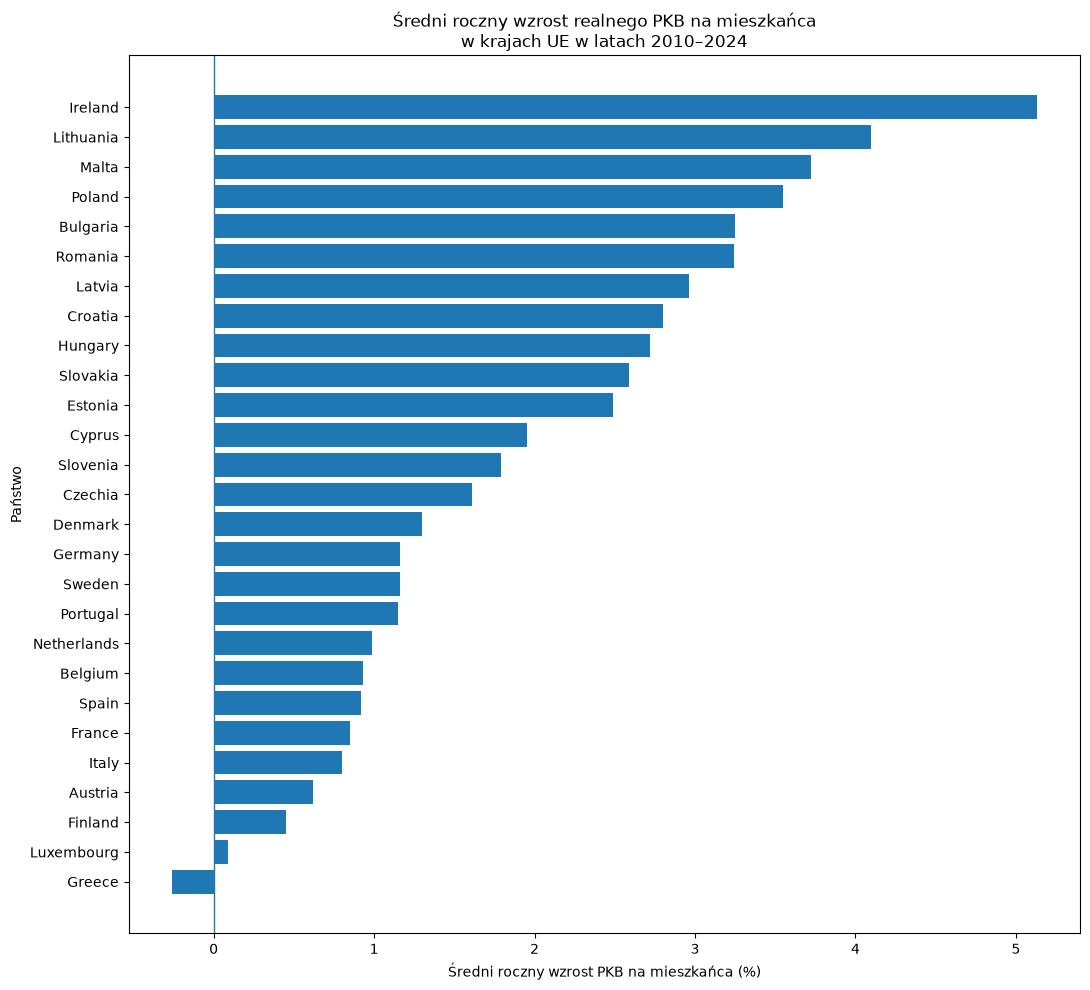

In [82]:
import matplotlib.pyplot as plt

# Sortowanie krajów od najniższej do najwyższej średniej
plot_data = country_means.sort_values(
    "gdp_growth",
    ascending=True
)

# Tworzenie wykresu
plt.figure(figsize=(11, 10))

plt.barh(
    plot_data["country"],
    plot_data["gdp_growth"]
)

# Linia oznaczająca zerowy wzrost
plt.axvline(0, linewidth=1)

plt.xlabel("Średni roczny wzrost PKB na mieszkańca (%)")
plt.ylabel("Państwo")
plt.title(
    "Średni roczny wzrost realnego PKB na mieszkańca\n"
    "w krajach UE w latach 2010–2024"
)

plt.tight_layout()
plt.show()

In [83]:
print("Statystyki opisowe wzrostu PKB:")
print(eu_gdp_check["gdp_growth"].describe().round(2))

Statystyki opisowe wzrostu PKB:
count    405.00
mean       1.93
std        3.57
min      -11.40
25%        0.30
50%        1.80
75%        4.00
max       23.50
Name: gdp_growth, dtype: float64


In [84]:
# Największy wzrost
max_growth = eu_gdp_check.loc[
    eu_gdp_check["gdp_growth"].idxmax()
]

# Największy spadek
min_growth = eu_gdp_check.loc[
    eu_gdp_check["gdp_growth"].idxmin()
]

print("NAJWIĘKSZY WZROST:")
print(max_growth[["country", "year", "gdp_growth"]])

print("\nNAJWIĘKSZY SPADEK:")
print(min_growth[["country", "year", "gdp_growth"]])

NAJWIĘKSZY WZROST:
country       Ireland
year             2015
gdp_growth       23.5
Name: 215, dtype: object

NAJWIĘKSZY SPADEK:
country       Spain
year           2020
gdp_growth    -11.4
Name: 145, dtype: object


In [85]:
# Zamieniamy rok na tekst, aby filtrowanie działało niezależnie od typu danych
years_as_text = eu_gdp_check["year"].astype(str)

# Irlandia: trzy lata wokół rekordowego wzrostu
ireland = eu_gdp_check[
    (eu_gdp_check["country_code"] == "IE") &
    (years_as_text.isin(["2014", "2015", "2016"]))
]

# Hiszpania: trzy lata wokół największego spadku
spain = eu_gdp_check[
    (eu_gdp_check["country_code"] == "ES") &
    (years_as_text.isin(["2019", "2020", "2021"]))
]

print("IRLANDIA:")
print(ireland[["country", "year", "gdp_growth", "status"]].to_string(index=False))

print("\nHISZPANIA:")
print(spain[["country", "year", "gdp_growth", "status"]].to_string(index=False))

IRLANDIA:
country  year  gdp_growth          status
Ireland  2014         8.6 brak oznaczenia
Ireland  2015        23.5 brak oznaczenia
Ireland  2016         0.0 brak oznaczenia

HISZPANIA:
country  year  gdp_growth          status
  Spain  2019         1.2 brak oznaczenia
  Spain  2020       -11.4 brak oznaczenia
  Spain  2021         6.7 brak oznaczenia


In [86]:
income_url = (
    "https://ec.europa.eu/eurostat/api/"
    "dissemination/statistics/1.0/data/ilc_di03"
)

response = requests.get(
    income_url,
    params={
        "geo": "PL",
        "sinceTimePeriod": "2010",
        "untilTimePeriod": "2024",
        "lang": "EN"
    }
)

response.raise_for_status()

income_data = response.json()

for dimension, details in income_data["dimension"].items():
    print(f"\nWYMIAR: {dimension}")

    categories = details["category"].get("label", {})

    for code, label in categories.items():
        print(f"{code}: {label}")


WYMIAR: freq
A: Annual

WYMIAR: age
TOTAL: Total
Y_LT6: Less than 6 years
Y6-10: From 6 to 10 years
Y6-11: From 6 to 11 years
Y11-15: From 11 to 15 years
Y12-17: From 12 to 17 years
Y_LT16: Less than 16 years
Y16-24: From 16 to 24 years
Y16-64: From 16 to 64 years
Y_GE16: 16 years or over
Y_LT18: Less than 18 years
Y18-24: From 18 to 24 years
Y18-64: From 18 to 64 years
Y_GE18: 18 years or over
Y25-49: From 25 to 49 years
Y25-54: From 25 to 54 years
Y50-64: From 50 to 64 years
Y55-64: From 55 to 64 years
Y_LT60: Less than 60 years
Y_GE60: 60 years or over
Y_LT65: Less than 65 years
Y65-74: From 65 to 74 years
Y_GE65: 65 years or over
Y_LT75: Less than 75 years
Y_GE75: 75 years or over

WYMIAR: sex
T: Total
M: Males
F: Females

WYMIAR: statinfo
MEAN_EI: Mean equivalised income
MED_EI: Median equivalised income

WYMIAR: unit
EUR: Euro
NAC: National currency
PPS: Purchasing power standard (PPS)

WYMIAR: geo
PL: Poland

WYMIAR: time
2010: 2010
2011: 2011
2012: 2012
2013: 2013
2014: 2014
2

In [87]:
income_params = {
    "freq": "A",
    "age": "TOTAL",
    "sex": "T",
    "statinfo": "MED_EI",
    "unit": "PPS",
    "geo": "PL",
    "sinceTimePeriod": "2010",
    "untilTimePeriod": "2024",
    "lang": "EN"
}

income_response = requests.get(
    income_url,
    params=income_params
)

income_response.raise_for_status()

income_pl_data = income_response.json()

print("Tytuł zbioru:")
print(income_pl_data["label"])

print("\nDostępne lata:")
print(
    list(
        income_pl_data["dimension"]["time"]
        ["category"]["index"].keys()
    )
)

Tytuł zbioru:
Mean and median income by age and sex

Dostępne lata:
['2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024']


In [88]:
def get_income_data(country_code, country_name):

    params = {
        "freq": "A",
        "age": "TOTAL",
        "sex": "T",
        "statinfo": "MED_EI",
        "unit": "PPS",
        "geo": country_code,
        "sinceTimePeriod": "2010",
        "untilTimePeriod": "2024",
        "lang": "EN"
    }

    response = requests.get(income_url, params=params)
    response.raise_for_status()

    data = response.json()

    years = list(
        data["dimension"]["time"]["category"]["index"].keys()
    )

    values = data.get("value", {})
    statuses = data.get("status", {})

    result = pd.DataFrame({
        "country_code": country_code,
        "country": country_name,
        "year": years,
        "median_income_pps": [
            values.get(str(i))
            for i in range(len(years))
        ],
        "status": [
            statuses.get(str(i), "brak oznaczenia")
            for i in range(len(years))
        ]
    })

    return result

In [89]:
poland_income = get_income_data("PL", "Poland")

print(poland_income.to_string(index=False))

country_code country year  median_income_pps          status
          PL  Poland 2010               7578 brak oznaczenia
          PL  Poland 2011               8322 brak oznaczenia
          PL  Poland 2012               8635 brak oznaczenia
          PL  Poland 2013               9158 brak oznaczenia
          PL  Poland 2014               9560 brak oznaczenia
          PL  Poland 2015               9950 brak oznaczenia
          PL  Poland 2016              10865 brak oznaczenia
          PL  Poland 2017              11079 brak oznaczenia
          PL  Poland 2018              11513 brak oznaczenia
          PL  Poland 2019              12335 brak oznaczenia
          PL  Poland 2020              13350 brak oznaczenia
          PL  Poland 2021              13870 brak oznaczenia
          PL  Poland 2022              14906 brak oznaczenia
          PL  Poland 2023              16551 brak oznaczenia
          PL  Poland 2024              18064 brak oznaczenia


In [90]:
debug_response = requests.get(
    income_url,
    params=income_params
)

debug_response.raise_for_status()
debug_data = debug_response.json()

print("Lata dostępne w wymiarze:")
print(
    debug_data["dimension"]["time"]["category"]["index"]
)

print("\nIndeksy dostępnych wartości:")
print(debug_data.get("value", {}).keys())

print("\nLiczba dostępnych wartości:")
print(len(debug_data.get("value", {})))

Lata dostępne w wymiarze:
{'2010': 0, '2011': 1, '2012': 2, '2013': 3, '2014': 4, '2015': 5, '2016': 6, '2017': 7, '2018': 8, '2019': 9, '2020': 10, '2021': 11, '2022': 12, '2023': 13, '2024': 14}

Indeksy dostępnych wartości:
dict_keys(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14'])

Liczba dostępnych wartości:
15


In [91]:
print("Wartość za 2024 rok:")
print(income_pl_data["value"].get("14"))

print("\nWartość za 2023 rok:")
print(income_pl_data["value"].get("13"))

Wartość za 2024 rok:
18064

Wartość za 2023 rok:
16551


In [92]:
print(
    poland_income[
        poland_income["year"] == "2024"
    ]
)

   country_code country  year  median_income_pps           status
14           PL  Poland  2024              18064  brak oznaczenia


In [93]:
import time

all_income_data = []

for code, country in eu_countries.items():
    try:
        country_df = get_income_data(code, country)

        all_income_data.append(country_df)

        print(f"Pobrano dane: {country}")

        time.sleep(0.2)

    except Exception as e:
        print(f"Błąd dla {country}: {e}")

eu_income_df = pd.concat(
    all_income_data,
    ignore_index=True
)

eu_income_df = eu_income_df.sort_values(
    ["country_code", "year"]
).reset_index(drop=True)

print("\nLiczba obserwacji:", len(eu_income_df))
print("Liczba państw:", eu_income_df["country_code"].nunique())

Pobrano dane: Austria
Pobrano dane: Belgium
Pobrano dane: Bulgaria
Pobrano dane: Croatia
Pobrano dane: Cyprus
Pobrano dane: Czechia
Pobrano dane: Denmark
Pobrano dane: Estonia
Pobrano dane: Finland
Pobrano dane: France
Pobrano dane: Germany
Pobrano dane: Hungary
Pobrano dane: Ireland
Pobrano dane: Italy
Pobrano dane: Latvia
Pobrano dane: Lithuania
Pobrano dane: Luxembourg
Pobrano dane: Malta
Pobrano dane: Netherlands
Pobrano dane: Poland
Pobrano dane: Portugal
Pobrano dane: Romania
Pobrano dane: Slovakia
Pobrano dane: Slovenia
Pobrano dane: Spain
Pobrano dane: Sweden
Pobrano dane: Greece

Liczba obserwacji: 405
Liczba państw: 27


In [94]:
print("Brakujące wartości:")
print(eu_income_df.isna().sum())

print("\nLiczba obserwacji na państwo:")
print(eu_income_df.groupby("country")["year"].count())

print("\nDuplikaty:")
print(
    eu_income_df.duplicated(
        subset=["country_code", "year"]
    ).sum()
)

Brakujące wartości:
country_code         0
country              0
year                 0
median_income_pps    0
status               0
dtype: int64

Liczba obserwacji na państwo:
country
Austria        15
Belgium        15
Bulgaria       15
Croatia        15
Cyprus         15
Czechia        15
Denmark        15
Estonia        15
Finland        15
France         15
Germany        15
Greece         15
Hungary        15
Ireland        15
Italy          15
Latvia         15
Lithuania      15
Luxembourg     15
Malta          15
Netherlands    15
Poland         15
Portugal       15
Romania        15
Slovakia       15
Slovenia       15
Spain          15
Sweden         15
Name: year, dtype: int64

Duplikaty:
0


In [95]:
# Ujednolicamy format kolumny year
eu_gdp_check["year"] = eu_gdp_check["year"].astype(str)
eu_income_df["year"] = eu_income_df["year"].astype(str)

# Łączymy dane według kraju i roku
eu_merged_df = pd.merge(
    eu_gdp_check,
    eu_income_df,
    on=["country_code", "country", "year"],
    how="inner",
    suffixes=("_gdp", "_income")
)

# Wyświetlamy podstawowe informacje
print("Liczba obserwacji:", len(eu_merged_df))
print("Liczba państw:", eu_merged_df["country_code"].nunique())

print("\nPierwsze obserwacje:")
print(eu_merged_df.head(10).to_string(index=False))

Liczba obserwacji: 405
Liczba państw: 27

Pierwsze obserwacje:
country_code country year  gdp_growth      status_gdp  median_income_pps   status_income
          AT Austria 2010         1.6 brak oznaczenia              19516 brak oznaczenia
          AT Austria 2011         2.6 brak oznaczenia              20425 brak oznaczenia
          AT Austria 2012         0.2 brak oznaczenia              20602 brak oznaczenia
          AT Austria 2013        -0.9 brak oznaczenia              20904 brak oznaczenia
          AT Austria 2014         0.0 brak oznaczenia              21662 brak oznaczenia
          AT Austria 2015         0.3 brak oznaczenia              21981 brak oznaczenia
          AT Austria 2016         0.8 brak oznaczenia              23071 brak oznaczenia
          AT Austria 2017         1.6 brak oznaczenia              23361 brak oznaczenia
          AT Austria 2018         2.0 brak oznaczenia              23204 brak oznaczenia
          AT Austria 2019         1.3 brak ozna

In [96]:
eu_merged_df.to_csv(
    "data/processed/eu_gdp_income_2010_2024.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Połączony zbiór danych został zapisany!")

Połączony zbiór danych został zapisany!


In [97]:
income_means = (
    eu_merged_df
    .groupby(["country_code", "country"])["median_income_pps"]
    .mean()
    .reset_index()
    .sort_values("median_income_pps", ascending=False)
)

income_means["median_income_pps"] = (
    income_means["median_income_pps"].round(2)
)

print("Średni poziom mediany dochodu w latach 2010–2024:")
print(income_means.to_string(index=False))

Średni poziom mediany dochodu w latach 2010–2024:
country_code     country  median_income_pps
          LU  Luxembourg           29723.27
          AT     Austria           23317.60
          NL Netherlands           21616.27
          DE     Germany           21424.07
          BE     Belgium           21301.53
          DK     Denmark           21190.53
          SE      Sweden           20241.07
          FR      France           20004.93
          FI     Finland           19857.80
          IE     Ireland           18848.13
          CY      Cyprus           18320.47
          MT       Malta           17531.60
          IT       Italy           16871.20
          SI    Slovenia           16220.33
          ES       Spain           15979.20
          CZ     Czechia           12828.33
          EE     Estonia           12076.47
          PL      Poland           11715.73
          PT    Portugal           11220.67
          LT   Lithuania           10216.27
          EL      Greece  

In [98]:
income_2024 = (
    eu_merged_df[
        eu_merged_df["year"] == "2024"
    ][["country_code", "country", "median_income_pps"]]
    .sort_values(
        "median_income_pps",
        ascending=False
    )
    .reset_index(drop=True)
)

income_2024.index += 1

print("MEDIANA DOCHODU EKWIWALENTNEGO — 2024")
print(income_2024.to_string())

MEDIANA DOCHODU EKWIWALENTNEGO — 2024
   country_code      country  median_income_pps
1            LU   Luxembourg              37781
2            AT      Austria              29758
3            NL  Netherlands              27091
4            BE      Belgium              26361
5            DE      Germany              25192
6            DK      Denmark              24297
7            SE       Sweden              23693
8            IE      Ireland              23288
9            FR       France              23222
10           FI      Finland              23055
11           CY       Cyprus              22817
12           MT        Malta              22077
13           SI     Slovenia              21572
14           IT        Italy              20804
15           ES        Spain              20800
16           PL       Poland              18064
17           CZ      Czechia              16972
18           EE      Estonia              16482
19           HR      Croatia              16277
20

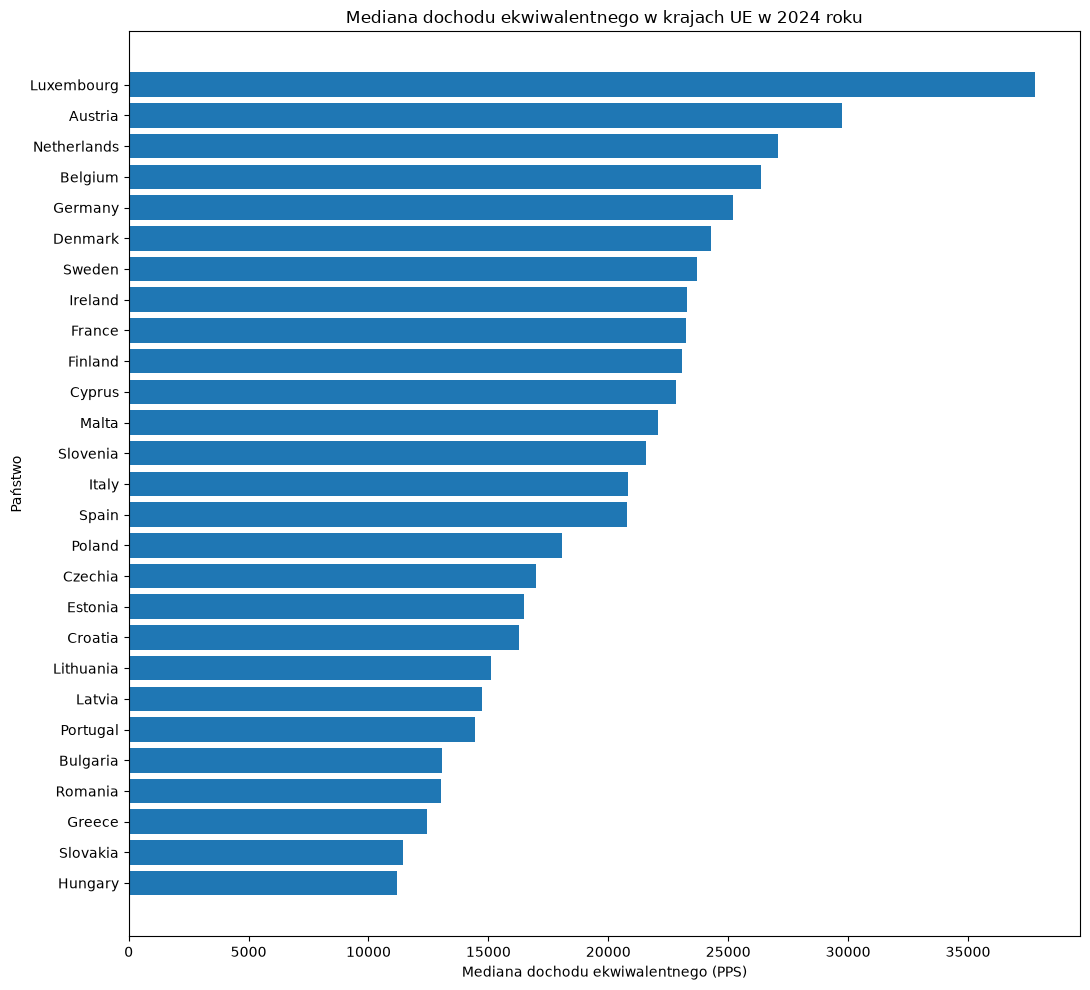

In [99]:
import matplotlib.pyplot as plt

plot_income = income_2024.sort_values(
    "median_income_pps",
    ascending=True
)

plt.figure(figsize=(11, 10))

plt.barh(
    plot_income["country"],
    plot_income["median_income_pps"]
)

plt.xlabel("Mediana dochodu ekwiwalentnego (PPS)")
plt.ylabel("Państwo")

plt.title(
    "Mediana dochodu ekwiwalentnego w krajach UE w 2024 roku"
)

plt.tight_layout()
plt.show()

In [100]:
# Dane z 2010 roku
income_2010 = eu_merged_df[
    eu_merged_df["year"] == "2010"
][["country_code", "country", "median_income_pps"]]

# Dane z 2024 roku
income_2024_values = eu_merged_df[
    eu_merged_df["year"] == "2024"
][["country_code", "median_income_pps"]]

# Łączymy oba lata
income_change = pd.merge(
    income_2010,
    income_2024_values,
    on="country_code",
    suffixes=("_2010", "_2024")
)

# Obliczamy zmianę procentową
income_change["income_change_pct"] = (
    (
        income_change["median_income_pps_2024"]
        - income_change["median_income_pps_2010"]
    )
    / income_change["median_income_pps_2010"]
) * 100

# Sortujemy wyniki
income_change = income_change.sort_values(
    "income_change_pct",
    ascending=False
)

income_change["income_change_pct"] = (
    income_change["income_change_pct"].round(2)
)

print(
    income_change[
        [
            "country",
            "median_income_pps_2010",
            "median_income_pps_2024",
            "income_change_pct"
        ]
    ].to_string(index=False)
)

    country  median_income_pps_2010  median_income_pps_2024  income_change_pct
    Romania                    3537                   13023             268.19
  Lithuania                    6018                   15110             151.08
     Latvia                    5876                   14721             150.53
     Poland                    7578                   18064             138.37
    Estonia                    7413                   16482             122.34
   Bulgaria                    5885                   13079             122.24
    Croatia                    7609                   16277             113.92
    Czechia                    9660                   16972              75.69
    Hungary                    6708                   11199              66.95
      Malta                   13371                   22077              65.11
   Slovenia                   13349                   21572              61.60
    Austria                   19516                 

In [101]:
income_params_nac = {
    "freq": "A",
    "age": "TOTAL",
    "sex": "T",
    "statinfo": "MED_EI",
    "unit": "NAC",
    "geo": "PL",
    "sinceTimePeriod": "2010",
    "untilTimePeriod": "2024",
    "lang": "EN"
}

response_nac = requests.get(income_url, params=income_params_nac)
response_nac.raise_for_status()

data_nac = response_nac.json()

years_nac = list(
    data_nac["dimension"]["time"]["category"]["index"].keys()
)

values_nac = data_nac.get("value", {})

poland_income_nac = pd.DataFrame({
    "year": years_nac,
    "median_income_nac": [
        values_nac.get(str(i))
        for i in range(len(years_nac))
    ]
})

display(poland_income_nac)

,year,median_income_nac
0,2010,19065
1,2011,20075
2,2012,20849
3,2013,21610
4,2014,22399
5,2015,23247
6,2016,24618
7,2017,25940
8,2018,27984
9,2019,30360


In [102]:
hicp_url = (
    "https://ec.europa.eu/eurostat/api/dissemination/"
    "statistics/1.0/data/prc_hicp_aind"
)

hicp_params = {
    "freq": "A",
    "unit": "INX_A_AVG",
    "coicop": "CP00",
    "geo": "PL",
    "sinceTimePeriod": "2010",
    "untilTimePeriod": "2024",
    "lang": "EN"
}

response_hicp = requests.get(hicp_url, params=hicp_params)
response_hicp.raise_for_status()

hicp_data = response_hicp.json()

hicp_years = list(
    hicp_data["dimension"]["time"]["category"]["index"].keys()
)

hicp_values = hicp_data.get("value", {})
hicp_statuses = hicp_data.get("status", {})

poland_hicp = pd.DataFrame({
    "year": hicp_years,
    "hicp_index": [
        hicp_values.get(str(i))
        for i in range(len(hicp_years))
    ],
    "status": [
        hicp_statuses.get(str(i), "brak oznaczenia")
        for i in range(len(hicp_years))
    ]
})

display(poland_hicp)

,year,hicp_index,status
0,2010,92.7,brak oznaczenia
1,2011,96.3,brak oznaczenia
2,2012,99.8,brak oznaczenia
3,2013,100.6,brak oznaczenia
4,2014,100.7,brak oznaczenia
5,2015,100.0,brak oznaczenia
6,2016,99.8,brak oznaczenia
7,2017,101.4,brak oznaczenia
8,2018,102.6,brak oznaczenia
9,2019,104.8,brak oznaczenia


In [103]:
income_params_2025 = {
    "freq": "A",
    "age": "TOTAL",
    "sex": "T",
    "statinfo": "MED_EI",
    "unit": "NAC",
    "geo": "PL",
    "sinceTimePeriod": "2011",
    "untilTimePeriod": "2025",
    "lang": "EN"
}

response_2025 = requests.get(income_url, params=income_params_2025)
response_2025.raise_for_status()

data_2025 = response_2025.json()

years_2025 = list(
    data_2025["dimension"]["time"]["category"]["index"].keys()
)

print("Dostępne lata:", years_2025)
print("Liczba obserwacji:", len(data_2025.get("value", {})))

Dostępne lata: ['2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
Liczba obserwacji: 15


In [104]:
# Pobieramy wartości dochodu z lat badania 2011–2025
income_values_2025 = data_2025.get("value", {})

# Tworzymy tabelę z latami odniesienia 2010–2024
poland_income_real = pd.DataFrame({
    "year": list(range(2010, 2025)),
    "median_income_nominal": [
        income_values_2025.get(str(i))
        for i in range(15)
    ]
})

# Łączymy dochody z indeksem HICP
poland_income_real = poland_income_real.merge(
    poland_hicp[["year", "hicp_index"]],
    on="year",
    how="left"
)

# Obliczamy dochód realny w cenach z 2015 roku
poland_income_real["median_income_real_2015"] = (
    poland_income_real["median_income_nominal"]
    / poland_income_real["hicp_index"]
    * 100
)

display(poland_income_real.round(2))

ValueError: You are trying to merge on int64 and str columns for key 'year'. If you wish to proceed you should use pd.concat

In [ ]:
poland_income_real["year"] = poland_income_real["year"].astype(int)
poland_hicp["year"] = poland_hicp["year"].astype(int)

In [ ]:
poland_income_real["year"] = poland_income_real["year"].astype(int)
poland_hicp["year"] = poland_hicp["year"].astype(int)

In [ ]:
poland_income_real = poland_income_real.merge(
    poland_hicp[["year", "hicp_index"]],
    on="year",
    how="left"
)

poland_income_real["median_income_real_2015"] = (
    poland_income_real["median_income_nominal"]
    / poland_income_real["hicp_index"]
    * 100
)

display(poland_income_real.round(2))

In [ ]:
income_2010 = poland_income_real.loc[
    poland_income_real["year"] == 2010,
    "median_income_real_2015"
].iloc[0]

income_2024 = poland_income_real.loc[
    poland_income_real["year"] == 2024,
    "median_income_real_2015"
].iloc[0]

real_income_change = (
    (income_2024 / income_2010) - 1
) * 100

print(f"Realna zmiana mediany dochodu: {real_income_change:.2f}%")

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    poland_income_real["year"],
    poland_income_real["median_income_real_2015"],
    marker="o"
)

plt.xlabel("Rok")
plt.ylabel("Mediana dochodu (zł, ceny z 2015 r.)")
plt.title("Realna mediana dochodu w Polsce w latach 2010–2024")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
poland_income_real.to_csv(
    "data/processed/poland_real_income_2010_2024.csv",
    index=False
)

print("Zapisano dane realnych dochodów dla Polski.")

In [ ]:
def get_hicp_data(country_code, country_name):

    params = {
        "freq": "A",
        "unit": "INX_A_AVG",
        "coicop": "CP00",
        "geo": country_code,
        "sinceTimePeriod": "2010",
        "untilTimePeriod": "2024",
        "lang": "EN"
    }

    response = requests.get(hicp_url, params=params)
    response.raise_for_status()

    data = response.json()

    years = list(
        data["dimension"]["time"]["category"]["index"].keys()
    )

    values = data.get("value", {})
    statuses = data.get("status", {})

    result = pd.DataFrame({
        "country_code": country_code,
        "country": country_name,
        "year": [int(year) for year in years],
        "hicp_index": [
            values.get(str(i))
            for i in range(len(years))
        ],
        "status_hicp": [
            statuses.get(str(i), "brak oznaczenia")
            for i in range(len(years))
        ]
    })

    return result

In [ ]:
germany_hicp = get_hicp_data("DE", "Germany")

display(germany_hicp)

In [ ]:
hicp_frames = []

for country_code, country_name in eu_countries.items():
    try:
        country_hicp = get_hicp_data(
            country_code,
            country_name
        )

        hicp_frames.append(country_hicp)

        print(f"Pobrano: {country_name}")

    except Exception as e:
        print(f"Błąd dla {country_name}: {e}")

eu_hicp_df = pd.concat(
    hicp_frames,
    ignore_index=True
)

display(eu_hicp_df.head())

In [ ]:
print("Liczba wierszy:", len(eu_hicp_df))
print("Liczba państw:", eu_hicp_df["country_code"].nunique())
print("Brakujące wartości:", eu_hicp_df["hicp_index"].isna().sum())

print(
    "Liczba duplikatów:",
    eu_hicp_df.duplicated(
        subset=["country_code", "year"]
    ).sum()
)

In [ ]:
eu_hicp_df.to_csv(
    "data/processed/eu_hicp_2010_2024.csv",
    index=False
)

print("Dane HICP zapisane!")

In [ ]:
print("eu_countries:", "eu_countries" in globals())
print("income_url:", "income_url" in globals())
print("hicp_url:", "hicp_url" in globals())
print("eu_hicp_df:", "eu_hicp_df" in globals())

In [ ]:
eu_countries = {
    "AT": "Austria",
    "BE": "Belgium",
    "BG": "Bulgaria",
    "HR": "Croatia",
    "CY": "Cyprus",
    "CZ": "Czechia",
    "DK": "Denmark",
    "EE": "Estonia",
    "FI": "Finland",
    "FR": "France",
    "DE": "Germany",
    "EL": "Greece",
    "HU": "Hungary",
    "IE": "Ireland",
    "IT": "Italy",
    "LV": "Latvia",
    "LT": "Lithuania",
    "LU": "Luxembourg",
    "MT": "Malta",
    "NL": "Netherlands",
    "PL": "Poland",
    "PT": "Portugal",
    "RO": "Romania",
    "SK": "Slovakia",
    "SI": "Slovenia",
    "ES": "Spain",
    "SE": "Sweden"
}

print("Liczba państw:", len(eu_countries))

In [ ]:
income_url = (
    "https://ec.europa.eu/eurostat/api/dissemination/"
    "statistics/1.0/data/ilc_di03"
)

hicp_url = (
    "https://ec.europa.eu/eurostat/api/dissemination/"
    "statistics/1.0/data/prc_hicp_aind"
)

eu_hicp_df = pd.read_csv(
    "data/processed/eu_hicp_2010_2024.csv"
)

print("Adresy API przywrócone.")
print("Liczba obserwacji HICP:", len(eu_hicp_df))
print("Liczba państw:", eu_hicp_df["country_code"].nunique())

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import time

print("Biblioteki zaimportowane poprawnie!")

In [ ]:
def get_income_nac_data(country_code, country_name):

    params = {
        "freq": "A",
        "age": "TOTAL",
        "sex": "T",
        "statinfo": "MED_EI",
        "unit": "NAC",
        "geo": country_code,
        "sinceTimePeriod": "2011",
        "untilTimePeriod": "2025",
        "lang": "EN"
    }

    response = requests.get(income_url, params=params)
    response.raise_for_status()

    data = response.json()

    years = list(
        data["dimension"]["time"]["category"]["index"].keys()
    )

    values = data.get("value", {})
    statuses = data.get("status", {})

    result = pd.DataFrame({
        "country_code": country_code,
        "country": country_name,
        "survey_year": [int(year) for year in years],
        "year": [int(year) - 1 for year in years],
        "median_income_nominal": [
            values.get(str(i))
            for i in range(len(years))
        ],
        "status_income": [
            statuses.get(str(i), "brak oznaczenia")
            for i in range(len(years))
        ]
    })

    return result

In [ ]:
poland_income_test = get_income_nac_data("PL", "Poland")

display(poland_income_test)

In [ ]:
def get_income_nac_data(country_code, country_name):

    params = {
        "freq": "A",
        "age": "TOTAL",
        "sex": "T",
        "statinfo": "MED_EI",
        "unit": "NAC",
        "geo": country_code,
        "sinceTimePeriod": "2011",
        "untilTimePeriod": "2025",
        "lang": "EN"
    }

    response = requests.get(income_url, params=params)
    response.raise_for_status()

    data = response.json()

    years = list(
        data["dimension"]["time"]["category"]["index"].keys()
    )

    values = data.get("value", {})
    statuses = data.get("status", {})

    result = pd.DataFrame({
        "country_code": country_code,
        "country": country_name,
        "survey_year": [int(y) for y in years],
        "year": [int(y) - 1 for y in years],
        "median_income_nominal": [
            values.get(str(i))
            for i in range(len(years))
        ],
        "status_income": [
            statuses.get(str(i), "brak oznaczenia")
            for i in range(len(years))
        ]
    })

    result["income_reference_period"] = "previous_calendar_year"

    if country_code == "IE":
        result.loc[
            result["survey_year"] <= 2019,
            "income_reference_period"
        ] = "rolling_12_months"

    return result

In [ ]:
ireland_test = get_income_nac_data("IE", "Ireland")

display(ireland_test)

In [ ]:
income_data = []

for code, country in eu_countries.items():
    country_df = get_income_nac_data(code, country)
    income_data.append(country_df)
    time.sleep(0.2)

eu_income_nac_df = pd.concat(income_data, ignore_index=True)

display(eu_income_nac_df.head())
print("Liczba obserwacji:", len(eu_income_nac_df))
print("Liczba państw:", eu_income_nac_df["country_code"].nunique())
print("Braki danych:", eu_income_nac_df["median_income_nominal"].isna().sum())

In [ ]:
eu_income_hicp_df = pd.merge(
    eu_income_nac_df,
    eu_hicp_df,
    on=["country_code", "country", "year"],
    how="left",
    validate="one_to_one"
)

display(eu_income_hicp_df.head())

print("Liczba obserwacji:", len(eu_income_hicp_df))
print("Braki w HICP:", eu_income_hicp_df["hicp_index"].isna().sum())

In [ ]:
eu_hicp_df = pd.read_csv(
    "data/processed/eu_hicp_2010_2024.csv"
)

print("Dane HICP zostały wczytane!")
print("Liczba obserwacji:", len(eu_hicp_df))
print("Liczba państw:", eu_hicp_df["country_code"].nunique())

In [ ]:
eu_income_hicp_df = pd.merge(
    eu_income_nac_df,
    eu_hicp_df,
    on=["country_code", "country", "year"],
    how="left",
    validate="one_to_one"
)

display(eu_income_hicp_df.head())

print("Liczba obserwacji:", len(eu_income_hicp_df))
print("Braki w HICP:", eu_income_hicp_df["hicp_index"].isna().sum())

In [ ]:
eu_income_hicp_df["real_income"] = (
    eu_income_hicp_df["median_income_nominal"]
    / eu_income_hicp_df["hicp_index"]
    * 100
)

In [ ]:
irish_rolling = (
    (eu_income_hicp_df["country_code"] == "IE")
    & (eu_income_hicp_df["income_reference_period"] == "rolling_12_months")
)

eu_income_hicp_df.loc[irish_rolling, "real_income"] = np.nan

In [ ]:
display(
    eu_income_hicp_df[
        ["country", "year", "median_income_nominal",
         "hicp_index", "real_income"]
    ].head(10)
)

print(
    "Braki w realnym dochodzie:",
    eu_income_hicp_df["real_income"].isna().sum()
)

In [ ]:
eu_income_hicp_df.to_csv(
    "data/processed/eu_real_median_income_2010_2024.csv",
    index=False
)

print("Zbiór danych został zapisany!")

In [ ]:
income_counts = (
    eu_income_hicp_df
    .groupby("country")["real_income"]
    .count()
    .sort_values()
)

display(income_counts)

In [ ]:
income_growth = (
    eu_income_hicp_df
    .dropna(subset=["real_income"])
    .sort_values("year")
    .groupby("country")
    .agg(
        income_2010=("real_income", "first"),
        income_2024=("real_income", "last"),
        first_year=("year", "min"),
        last_year=("year", "max")
    )
    .reset_index()
)

income_growth["real_income_growth_pct"] = (
    (income_growth["income_2024"] / income_growth["income_2010"] - 1) * 100
)

display(
    income_growth.sort_values(
        "real_income_growth_pct",
        ascending=False
    ).round(2)
)

In [ ]:
# Kopia danych – zachowujemy oryginalny zbiór
eu_income_hicp_df["real_income_eur"] = (
    eu_income_hicp_df["real_income"]
)

# Litwa: dane do 2014 r. były wyrażone w litach
lithuania_mask = (
    (eu_income_hicp_df["country_code"] == "LT")
    & (eu_income_hicp_df["year"] < 2015)
)

eu_income_hicp_df.loc[
    lithuania_mask, "real_income_eur"
] = (
    eu_income_hicp_df.loc[
        lithuania_mask, "real_income"
    ] / 3.4528
)

# Chorwacja: dane do 2022 r. były wyrażone w kunach
croatia_mask = (
    (eu_income_hicp_df["country_code"] == "HR")
    & (eu_income_hicp_df["year"] < 2023)
)

eu_income_hicp_df.loc[
    croatia_mask, "real_income_eur"
] = (
    eu_income_hicp_df.loc[
        croatia_mask, "real_income"
    ] / 7.53450
)

print("Korekta walutowa została wykonana.")

In [ ]:
display(
    eu_income_hicp_df[
        eu_income_hicp_df["country_code"].isin(["LT", "HR"])
    ][
        ["country", "year", "real_income", "real_income_eur"]
    ]
)

In [ ]:
# Zaczynamy od ponownego skopiowania oryginalnych wartości
eu_income_hicp_df["real_income_eur"] = (
    eu_income_hicp_df["real_income"]
)

# Litwa: przeliczenie do euro do 2013 roku włącznie
lithuania_mask = (
    (eu_income_hicp_df["country_code"] == "LT")
    & (eu_income_hicp_df["year"] <= 2013)
)

eu_income_hicp_df.loc[
    lithuania_mask, "real_income_eur"
] = (
    eu_income_hicp_df.loc[
        lithuania_mask, "real_income"
    ] / 3.4528
)

# Chorwacja: przeliczenie do euro do 2021 roku włącznie
croatia_mask = (
    (eu_income_hicp_df["country_code"] == "HR")
    & (eu_income_hicp_df["year"] <= 2021)
)

eu_income_hicp_df.loc[
    croatia_mask, "real_income_eur"
] = (
    eu_income_hicp_df.loc[
        croatia_mask, "real_income"
    ] / 7.53450
)

print("Korekta walutowa została zaktualizowana.")

In [ ]:
display(
    eu_income_hicp_df[
        eu_income_hicp_df["country_code"].isin(["LT", "HR"])
    ][
        ["country", "survey_year", "year",
         "real_income", "real_income_eur"]
    ]
)

In [ ]:
income_growth = (
    eu_income_hicp_df
    .dropna(subset=["real_income_eur"])
    .sort_values("year")
    .groupby("country")
    .agg(
        income_first=("real_income_eur", "first"),
        income_last=("real_income_eur", "last"),
        first_year=("year", "min"),
        last_year=("year", "max")
    )
    .reset_index()
)

income_growth["real_income_growth_pct"] = (
    (income_growth["income_last"] /
     income_growth["income_first"] - 1) * 100
)

income_growth = income_growth.sort_values(
    "real_income_growth_pct",
    ascending=False
)

display(income_growth.round(2))

In [ ]:
eu_income_hicp_df = eu_income_hicp_df.rename(
    columns={
        "real_income_eur": "real_income_stable_unit"
    }
)

eu_income_hicp_df.to_csv(
    "data/processed/eu_real_median_income_2010_2024.csv",
    index=False
)

print("Poprawiony zbiór danych został zapisany.")

In [ ]:
# Wczytanie danych o wzroście PKB
eu_gdp_check = pd.read_csv(
    "data/processed/gdp_growth_eu27_2010_2024.csv"
)

# Średni roczny wzrost PKB na mieszkańca
gdp_growth_country = (
    eu_gdp_check
    .groupby(["country_code", "country"])
    .agg(
        avg_gdp_growth=("gdp_growth", "mean")
    )
    .reset_index()
)

display(
    gdp_growth_country.sort_values(
        "avg_gdp_growth",
        ascending=False
    ).round(2)
)

print("Liczba państw:", len(gdp_growth_country))

In [ ]:
# Pomijamy Irlandię w głównej analizie
income_data_main = eu_income_hicp_df[
    (eu_income_hicp_df["country_code"] != "IE")
    & (eu_income_hicp_df["year"].isin([2010, 2024]))
].copy()

income_growth_country = (
    income_data_main
    .pivot(
        index=["country_code", "country"],
        columns="year",
        values="real_income_stable_unit"
    )
    .reset_index()
)

income_growth_country["annual_real_income_growth"] = (
    (
        income_growth_country[2024]
        / income_growth_country[2010]
    ) ** (1 / 14) - 1
) * 100

display(
    income_growth_country[
        ["country", 2010, 2024, "annual_real_income_growth"]
    ].round(2)
)

print("Liczba państw:", len(income_growth_country))

In [ ]:
# Łączymy dane o PKB i realnych dochodach
analysis_df = pd.merge(
    gdp_growth_country,
    income_growth_country[
        ["country_code", "annual_real_income_growth"]
    ],
    on="country_code",
    how="inner",
    validate="one_to_one"
)

# Porządkujemy tabelę
analysis_df = analysis_df.sort_values("country")

# Wyświetlamy wyniki
display(analysis_df.round(2))

# Kontrola poprawności
print("Liczba państw:", len(analysis_df))
print("Brakujące wartości:")
print(analysis_df.isna().sum())

In [ ]:
from scipy.stats import pearsonr, spearmanr

# Wybieramy analizowane zmienne
x = analysis_df["avg_gdp_growth"]
y = analysis_df["annual_real_income_growth"]

# Korelacja Pearsona
pearson_corr, pearson_p = pearsonr(x, y)

# Korelacja Spearmana
spearman_corr, spearman_p = spearmanr(x, y)

print("KORELACJA PEARSONA")
print(f"Współczynnik: {pearson_corr:.3f}")
print(f"Wartość p: {pearson_p:.4f}")

print("\nKORELACJA SPEARMANA")
print(f"Współczynnik: {spearman_corr:.3f}")
print(f"Wartość p: {spearman_p:.4f}")

In [ ]:
plt.figure(figsize=(10, 7))

sns.regplot(
    data=analysis_df,
    x="avg_gdp_growth",
    y="annual_real_income_growth",
    ci=95,
    scatter_kws={"s": 70},
    line_kws={"linewidth": 2}
)

plt.xlabel("Średni roczny wzrost realnego PKB na mieszkańca (%)")
plt.ylabel("Średnioroczny wzrost realnych dochodów (%)")
plt.title(
    "Wzrost PKB a wzrost realnych dochodów\n"
    "w krajach UE (2010–2024)"
)

plt.tight_layout()
plt.show()

In [ ]:
print(f"Pearson p-value: {pearson_p:.2e}")
print(f"Spearman p-value: {spearman_p:.2e}")

In [ ]:
# 5 państw z najwyższym wzrostem realnych dochodów
print("NAJWYŻSZY WZROST DOCHODÓW")

display(
    analysis_df.nlargest(
        5, "annual_real_income_growth"
    )[
        ["country", "avg_gdp_growth", "annual_real_income_growth"]
    ].round(2)
)

# 5 państw z najniższym wzrostem realnych dochodów
print("NAJNIŻSZY WZROST DOCHODÓW")

display(
    analysis_df.nsmallest(
        5, "annual_real_income_growth"
    )[
        ["country", "avg_gdp_growth", "annual_real_income_growth"]
    ].round(2)
)

In [ ]:
# Analiza wrażliwości korelacji Pearsona
sensitivity_results = []

for country in analysis_df["country"]:

    temp_df = analysis_df[
        analysis_df["country"] != country
    ]

    corr, p_value = pearsonr(
        temp_df["avg_gdp_growth"],
        temp_df["annual_real_income_growth"]
    )

    sensitivity_results.append({
        "excluded_country": country,
        "pearson_correlation": corr,
        "p_value": p_value
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(
    sensitivity_df.sort_values(
        "pearson_correlation"
    ).round(4)
)

In [ ]:
plt.figure(figsize=(13, 9))

sns.regplot(
    data=analysis_df,
    x="avg_gdp_growth",
    y="annual_real_income_growth",
    ci=95,
    scatter_kws={"s": 65},
    line_kws={"linewidth": 2}
)

# Dodanie nazw państw
for _, row in analysis_df.iterrows():
    plt.annotate(
        row["country"],
        (
            row["avg_gdp_growth"],
            row["annual_real_income_growth"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Średni roczny wzrost realnego PKB na mieszkańca (%)")
plt.ylabel("Średnioroczny wzrost realnych dochodów (%)")
plt.title("Zależność między wzrostem PKB a wzrostem dochodów – UE")

plt.tight_layout()
plt.show()

In [ ]:
employment_url = (
    "https://ec.europa.eu/eurostat/api/"
    "dissemination/statistics/1.0/data/lfsi_emp_a"
)

params = {
    "freq": "A",
    "age": "Y20-64",
    "sex": "T",
    "indic_em": "EMP_LFS",
    "unit": "PC_POP",
    "geo": "PL",
    "sinceTimePeriod": "2010",
    "untilTimePeriod": "2024",
    "lang": "EN"
}

response = requests.get(employment_url, params=params)
response.raise_for_status()

employment_test = response.json()

print("Tytuł zbioru:", employment_test["label"])
print("Wymiary:", list(employment_test["dimension"].keys()))

In [ ]:
def get_employment_data(country_code, country_name):

    params = {
        "freq": "A",
        "age": "Y20-64",
        "sex": "T",
        "indic_em": "EMP_LFS",
        "unit": "PC_POP",
        "geo": country_code,
        "sinceTimePeriod": "2010",
        "untilTimePeriod": "2024",
        "lang": "EN"
    }

    response = requests.get(employment_url, params=params)
    response.raise_for_status()

    data = response.json()

    years = list(
        data["dimension"]["time"]["category"]["index"].keys()
    )

    values = data.get("value", {})
    statuses = data.get("status", {})

    result = pd.DataFrame({
        "country_code": country_code,
        "country": country_name,
        "year": [int(year) for year in years],
        "employment_rate": [
            values.get(str(i))
            for i in range(len(years))
        ],
        "status_employment": [
            statuses.get(str(i), "brak oznaczenia")
            for i in range(len(years))
        ]
    })

    return result

In [ ]:
poland_employment = get_employment_data("PL", "Poland")

display(poland_employment)

print("Liczba obserwacji:", len(poland_employment))
print("Brakujące wartości:", poland_employment["employment_rate"].isna().sum())

In [ ]:
employment_data = []

for country_code, country_name in eu_countries.items():

    try:
        country_df = get_employment_data(
            country_code,
            country_name
        )

        employment_data.append(country_df)

        print(f"Pobrano dane: {country_name}")

        time.sleep(0.2)

    except Exception as e:
        print(f"Błąd dla {country_name}: {e}")


eu_employment_df = pd.concat(
    employment_data,
    ignore_index=True
)

display(eu_employment_df.head())

In [ ]:
print("Liczba obserwacji:", len(eu_employment_df))

print(
    "Liczba państw:",
    eu_employment_df["country_code"].nunique()
)

print(
    "Brakujące wartości:",
    eu_employment_df["employment_rate"].isna().sum()
)

print(
    "Duplikaty:",
    eu_employment_df.duplicated(
        subset=["country_code", "year"]
    ).sum()
)

print("\nLiczba obserwacji na państwo:")
display(
    eu_employment_df.groupby("country").size()
)

In [ ]:
eu_employment_df.to_csv(
    "data/processed/eu_employment_2010_2024.csv",
    index=False
)

print("Dane o zatrudnieniu zostały zapisane.")

In [ ]:
employment_change = (
    eu_employment_df
    .pivot(
        index=["country_code", "country"],
        columns="year",
        values="employment_rate"
    )
    .reset_index()
)

employment_change["employment_change_pp"] = (
    employment_change[2024] - employment_change[2010]
)

employment_change = employment_change.sort_values(
    "employment_change_pp",
    ascending=False
)

display(
    employment_change[
        ["country", 2010, 2024, "employment_change_pp"]
    ].round(2)
)

In [ ]:
plot_employment = employment_change.sort_values(
    "employment_change_pp",
    ascending=True
)

plt.figure(figsize=(11, 9))

plt.barh(
    plot_employment["country"],
    plot_employment["employment_change_pp"]
)

plt.axvline(0, linewidth=1)

plt.xlabel("Zmiana wskaźnika zatrudnienia (punkty procentowe)")
plt.ylabel("Państwo")
plt.title(
    "Zmiana wskaźnika zatrudnienia osób w wieku 20–64 lata\n"
    "w krajach UE w latach 2010–2024"
)

plt.tight_layout()
plt.show()

In [ ]:
employment_analysis = pd.merge(
    gdp_growth_country,
    employment_change[
        ["country_code", "employment_change_pp"]
    ],
    on="country_code",
    how="inner",
    validate="one_to_one"
)

display(employment_analysis.round(2))

print("Liczba państw:", len(employment_analysis))
print("Brakujące wartości:")
print(employment_analysis.isna().sum())

In [ ]:
from scipy.stats import pearsonr, spearmanr

x = employment_analysis["avg_gdp_growth"]
y = employment_analysis["employment_change_pp"]

# Korelacja Pearsona
pearson_emp, p_pearson_emp = pearsonr(x, y)

# Korelacja Spearmana
spearman_emp, p_spearman_emp = spearmanr(x, y)

print("KORELACJA PEARSONA")
print(f"Współczynnik: {pearson_emp:.3f}")
print(f"Wartość p: {p_pearson_emp:.4e}")

print("\nKORELACJA SPEARMANA")
print(f"Współczynnik: {spearman_emp:.3f}")
print(f"Wartość p: {p_spearman_emp:.4e}")

In [ ]:
plt.figure(figsize=(10, 7))

sns.regplot(
    data=employment_analysis,
    x="avg_gdp_growth",
    y="employment_change_pp",
    ci=95,
    scatter_kws={"s": 70},
    line_kws={"linewidth": 2}
)

plt.title(
    "Wzrost PKB a zmiana wskaźnika zatrudnienia w krajach UE (2010–2024)"
)
plt.xlabel("Średni roczny wzrost realnego PKB na mieszkańca (%)")
plt.ylabel("Zmiana wskaźnika zatrudnienia (punkty procentowe)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "figures/gdp_employment_relationship.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [ ]:
correlation_summary = pd.DataFrame({
    "relationship": [
        "GDP growth and real income growth",
        "GDP growth and employment change"
    ],
    "pearson": [0.866, 0.810],
    "spearman": [0.845, 0.818],
    "observations": [26, 27],
    "p_value": ["<0.001", "<0.001"]
})

display(correlation_summary)

correlation_summary.to_csv(
    "data/processed/correlation_summary.csv",
    index=False
)

In [ ]:
display(correlation_summary)

In [ ]:
arope_url = (
    "https://ec.europa.eu/eurostat/api/dissemination/"
    "statistics/1.0/data/ilc_peps01n"
)

def get_arope_data(country_code, country_name):
    params = {
        "freq": "A",
        "unit": "PC",
        "age": "TOTAL",
        "sex": "T",
        "geo": country_code,
        "sinceTimePeriod": "2015",
        "untilTimePeriod": "2024",
        "lang": "EN"
    }

    response = requests.get(arope_url, params=params)
    response.raise_for_status()

    data = response.json()

    years = list(
        data["dimension"]["time"]["category"]["index"].keys()
    )

    values = data.get("value", {})
    statuses = data.get("status", {})

    result = pd.DataFrame({
        "country_code": country_code,
        "country": country_name,
        "year": [int(year) for year in years],
        "arope_rate": [
            values.get(str(i))
            for i in range(len(years))
        ],
        "status_arope": [
            statuses.get(str(i), "brak oznaczenia")
            for i in range(len(years))
        ]
    })

    return result

In [ ]:
poland_arope = get_arope_data("PL", "Poland")

display(poland_arope)
print("Liczba obserwacji:", len(poland_arope))
print("Brakujące wartości:")
print(poland_arope.isna().sum())

In [ ]:
arope_data = []

for code, name in eu_countries.items():
    try:
        country_df = get_arope_data(code, name)
        arope_data.append(country_df)
        print(f"Pobrano: {name}")
        time.sleep(0.2)

    except Exception as e:
        print(f"Błąd dla {name}: {e}")

eu_arope_df = pd.concat(
    arope_data,
    ignore_index=True
)

display(eu_arope_df.head())

In [ ]:
print("Liczba obserwacji:", len(eu_arope_df))
print("Liczba państw:", eu_arope_df["country_code"].nunique())

print("\nLiczba obserwacji na państwo:")
print(
    eu_arope_df.groupby("country")["year"].count()
)

print("\nBrakujące wartości:")
print(eu_arope_df.isna().sum())

print("\nDuplikaty:")
print(
    eu_arope_df.duplicated(
        subset=["country_code", "year"]
    ).sum()
)

In [ ]:
eu_arope_df.to_csv(
    "data/processed/eu_arope_2015_2024.csv",
    index=False
)

In [ ]:
arope_change = (
    eu_arope_df[
        eu_arope_df["year"].isin([2015, 2024])
    ]
    .pivot(
        index=["country_code", "country"],
        columns="year",
        values="arope_rate"
    )
    .reset_index()
)

arope_change["change_pp"] = (
    arope_change[2024] - arope_change[2015]
)

arope_change = arope_change.sort_values(
    "change_pp"
)

display(arope_change.round(2))

In [ ]:
print(
    "Średnia zmiana AROPE w UE:",
    round(arope_change["change_pp"].mean(), 2),
    "p.p."
)

print("\nNajwiększy spadek AROPE:")
display(arope_change.head(5))

print("\nNajwiększy wzrost AROPE:")
display(arope_change.tail(5))

In [ ]:
gdp_2015_2024 = (
    eu_gdp_check[
        eu_gdp_check["year"].between(2015, 2024)
    ]
    .groupby(["country_code", "country"])
    .agg(
        avg_gdp_growth_2015_2024=("gdp_growth", "mean")
    )
    .reset_index()
)

In [ ]:
arope_analysis = pd.merge(
    gdp_2015_2024,
    arope_change[
        ["country_code", "change_pp"]
    ],
    on="country_code",
    how="inner",
    validate="one_to_one"
)

display(arope_analysis.round(2))

print("Liczba państw:", len(arope_analysis))
print("Brakujące wartości:")
print(arope_analysis.isna().sum())

In [ ]:
from scipy.stats import pearsonr, spearmanr

x = arope_analysis["avg_gdp_growth_2015_2024"]
y = arope_analysis["change_pp"]

pearson_arope, p_pearson_arope = pearsonr(x, y)
spearman_arope, p_spearman_arope = spearmanr(x, y)

print("KORELACJA PEARSONA")
print(f"Współczynnik: {pearson_arope:.3f}")
print(f"Wartość p: {p_pearson_arope:.4e}")

print("\nKORELACJA SPEARMANA")
print(f"Współczynnik: {spearman_arope:.3f}")
print(f"Wartość p: {p_spearman_arope:.4e}")

In [ ]:
plt.figure(figsize=(10, 7))

sns.regplot(
    data=arope_analysis,
    x="avg_gdp_growth_2015_2024",
    y="change_pp",
    ci=95,
    scatter_kws={"s": 70},
    line_kws={"linewidth": 2}
)

plt.title(
    "Wzrost PKB a zmiana wskaźnika AROPE w krajach UE (2015–2024)"
)
plt.xlabel("Średni roczny wzrost realnego PKB na mieszkańca (%)")
plt.ylabel("Zmiana AROPE (punkty procentowe)")
plt.axhline(0, linewidth=1, linestyle="--")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "figures/gdp_arope_relationship.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
arope_result = pd.DataFrame({
    "relationship": ["GDP growth and AROPE change"],
    "pearson": [pearson_arope],
    "spearman": [spearman_arope],
    "observations": [len(arope_analysis)],
    "p_value": ["<0.001"]
})

correlation_summary = pd.concat(
    [correlation_summary, arope_result],
    ignore_index=True
)

display(correlation_summary.round(3))

correlation_summary.to_csv(
    "data/processed/correlation_summary.csv",
    index=False
)

In [ ]:
life_expectancy_url = (
    "https://ec.europa.eu/eurostat/api/dissemination/"
    "statistics/1.0/data/demo_mlexpec"
)

def get_life_expectancy_data(country_code, country_name):
    params = {
        "freq": "A",
        "unit": "YR",
        "sex": "T",
        "age": "Y_LT1",
        "geo": country_code,
        "sinceTimePeriod": "2010",
        "untilTimePeriod": "2024",
        "lang": "EN"
    }

    response = requests.get(life_expectancy_url, params=params)
    response.raise_for_status()

    data = response.json()

    years = list(
        data["dimension"]["time"]["category"]["index"].keys()
    )

    values = data.get("value", {})
    statuses = data.get("status", {})

    result = pd.DataFrame({
        "country_code": country_code,
        "country": country_name,
        "year": [int(year) for year in years],
        "life_expectancy": [
            values.get(str(i))
            for i in range(len(years))
        ],
        "status_life": [
            statuses.get(str(i), "brak oznaczenia")
            for i in range(len(years))
        ]
    })

    return result

In [ ]:
poland_life = get_life_expectancy_data("PL", "Poland")

display(poland_life)

print("Liczba obserwacji:", len(poland_life))
print("Brakujące wartości:")
print(poland_life.isna().sum())

In [ ]:
life_data = []

for code, name in eu_countries.items():
    try:
        country_df = get_life_expectancy_data(code, name)
        life_data.append(country_df)
        print(f"Pobrano: {name}")
        time.sleep(0.2)

    except Exception as e:
        print(f"Błąd dla {name}: {e}")

eu_life_df = pd.concat(
    life_data,
    ignore_index=True
)

display(eu_life_df.head())

In [ ]:
print("Liczba obserwacji:", len(eu_life_df))
print("Liczba państw:", eu_life_df["country_code"].nunique())

print("\nLiczba obserwacji na państwo:")
print(eu_life_df.groupby("country")["year"].count())

print("\nBrakujące wartości:")
print(eu_life_df.isna().sum())

print("\nDuplikaty:")
print(
    eu_life_df.duplicated(
        subset=["country_code", "year"]
    ).sum()
)

In [ ]:
eu_life_df.to_csv(
    "data/processed/eu_life_expectancy_2010_2024.csv",
    index=False
)

print("Zapisano dane o oczekiwanej długości życia.")

In [ ]:
life_change = (
    eu_life_df[
        eu_life_df["year"].isin([2010, 2024])
    ]
    .pivot(
        index=["country_code", "country"],
        columns="year",
        values="life_expectancy"
    )
    .reset_index()
)

life_change["life_expectancy_change"] = (
    life_change[2024] - life_change[2010]
)

life_change = life_change.sort_values(
    "life_expectancy_change",
    ascending=False
)

display(
    life_change[
        [
            "country",
            2010,
            2024,
            "life_expectancy_change"
        ]
    ].round(1)
)

print(
    "Średnia zmiana w UE-27:",
    round(life_change["life_expectancy_change"].mean(), 2),
    "lat"
)

In [ ]:
eu_life_df.to_csv(
    "data/processed/eu_life_expectancy_2010_2024.csv",
    index=False
)

print("Dane zapisano pomyślnie.")

In [ ]:
life_expectancy_change = (
    eu_life_df[
        eu_life_df["year"].isin([2010, 2024])
    ]
    .pivot(
        index=["country_code", "country"],
        columns="year",
        values="life_expectancy"
    )
    .reset_index()
)

life_expectancy_change["life_expectancy_change"] = (
    life_expectancy_change[2024]
    - life_expectancy_change[2010]
)

life_expectancy_change = life_expectancy_change.sort_values(
    "life_expectancy_change",
    ascending=False
)

display(life_expectancy_change.round(2))

In [ ]:
print("Dane PKB:", len(eu_gdp_check))
print("Dane o długości życia:", len(eu_life_df))
print("Dane o dochodach:", len(eu_income_hicp_df))
print("Dane o zatrudnieniu:", len(eu_employment_df))
print("Dane AROPE:", len(eu_arope_df))

In [ ]:
import pandas as pd

eu_gdp_check = pd.read_csv(
    "data/processed/gdp_growth_eu27_2010_2024.csv"
)

print("Dane PKB:", len(eu_gdp_check))
display(eu_gdp_check.head())

In [ ]:
eu_life_df = pd.read_csv(
    "data/processed/eu_life_expectancy_2010_2024.csv"
)

eu_income_hicp_df = pd.read_csv(
    "data/processed/eu_real_median_income_2010_2024.csv"
)

eu_employment_df = pd.read_csv(
    "data/processed/eu_employment_2010_2024.csv"
)

eu_arope_df = pd.read_csv(
    "data/processed/eu_arope_2015_2024.csv"
)

print("Przywrócono wszystkie pozostałe zbiory danych!")

In [ ]:
print("Dane PKB:", len(eu_gdp_check))
print("Dane o długości życia:", len(eu_life_df))
print("Dane o dochodach:", len(eu_income_hicp_df))
print("Dane o zatrudnieniu:", len(eu_employment_df))
print("Dane AROPE:", len(eu_arope_df))

In [ ]:
life_expectancy_change = (
    eu_life_df[
        eu_life_df["year"].isin([2010, 2024])
    ]
    .pivot(
        index=["country_code", "country"],
        columns="year",
        values="life_expectancy"
    )
    .reset_index()
)

life_expectancy_change["life_expectancy_change"] = (
    life_expectancy_change[2024]
    - life_expectancy_change[2010]
)

life_expectancy_change = life_expectancy_change.sort_values(
    "life_expectancy_change",
    ascending=False
)

display(life_expectancy_change.round(2))

In [ ]:
gdp_growth_country = (
    eu_gdp_check
    .groupby(["country_code", "country"])
    .agg(
        avg_gdp_growth=("gdp_growth", "mean")
    )
    .reset_index()
)

display(gdp_growth_country.head())

In [ ]:
life_expectancy_analysis = pd.merge(
    gdp_growth_country,
    life_expectancy_change[
        ["country_code", "life_expectancy_change"]
    ],
    on="country_code",
    how="inner",
    validate="one_to_one"
)

display(life_expectancy_analysis.round(2))

In [ ]:
print("Liczba państw:", len(life_expectancy_analysis))
print(
    "Brakujące wartości:",
    life_expectancy_analysis.isna().sum().sum()
)

In [ ]:
from scipy.stats import pearsonr, spearmanr

pearson_life, p_pearson_life = pearsonr(
    life_expectancy_analysis["avg_gdp_growth"],
    life_expectancy_analysis["life_expectancy_change"]
)

spearman_life, p_spearman_life = spearmanr(
    life_expectancy_analysis["avg_gdp_growth"],
    life_expectancy_analysis["life_expectancy_change"]
)

print("Korelacja Pearsona:", round(pearson_life, 3))
print("Wartość p Pearsona:", round(p_pearson_life, 5))

print("\nKorelacja Spearmana:", round(spearman_life, 3))
print("Wartość p Spearmana:", round(p_spearman_life, 5))

In [ ]:
plt.figure(figsize=(10, 7))

sns.regplot(
    data=life_expectancy_analysis,
    x="avg_gdp_growth",
    y="life_expectancy_change",
    ci=95,
    scatter_kws={"s": 70},
    line_kws={"linewidth": 2}
)

plt.title(
    "Wzrost PKB a zmiana oczekiwanej długości życia w krajach UE (2010–2024)"
)

plt.xlabel("Średni roczny wzrost realnego PKB na mieszkańca (%)")
plt.ylabel("Zmiana oczekiwanej długości życia (lata)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/gdp_life_expectancy_relationship.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import time

from scipy.stats import pearsonr, spearmanr

print("Biblioteki załadowane poprawnie!")

In [ ]:
plt.figure(figsize=(10, 7))

sns.regplot(
    data=life_expectancy_analysis,
    x="avg_gdp_growth",
    y="life_expectancy_change",
    ci=95,
    scatter_kws={"s": 70},
    line_kws={"linewidth": 2}
)

plt.title(
    "Wzrost PKB a zmiana oczekiwanej długości życia w krajach UE (2010–2024)"
)

plt.xlabel("Średni roczny wzrost realnego PKB na mieszkańca (%)")
plt.ylabel("Zmiana oczekiwanej długości życia (lata)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/gdp_life_expectancy_relationship.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
life_result = pd.DataFrame({
    "relationship": ["GDP growth and life expectancy change"],
    "pearson": [pearson_life],
    "spearman": [spearman_life],
    "observations": [len(life_expectancy_analysis)],
    "p_value": ["<0.05"]
})

correlation_summary = pd.concat(
    [correlation_summary, life_result],
    ignore_index=True
)

display(correlation_summary.round(3))

In [ ]:
correlation_summary = pd.read_csv(
    "data/processed/correlation_summary.csv"
)

display(correlation_summary)

In [ ]:
life_result = pd.DataFrame({
    "relationship": ["GDP growth and life expectancy change"],
    "pearson": [pearson_life],
    "spearman": [spearman_life],
    "observations": [len(life_expectancy_analysis)],
    "p_value": ["<0.05"]
})

correlation_summary = pd.concat(
    [correlation_summary, life_result],
    ignore_index=True
)

display(correlation_summary.round(3))

In [ ]:
correlation_summary.to_csv(
    "data/processed/correlation_summary.csv",
    index=False
)

print("Podsumowanie zapisane!")

In [ ]:
import statsmodels.api as sm

print("Biblioteka statsmodels załadowana poprawnie!")

In [ ]:
X = income_analysis["avg_gdp_growth"]
y = income_analysis["annual_real_income_growth"]

X = sm.add_constant(X)

income_model = sm.OLS(y, X).fit()

print(income_model.summary())

In [ ]:
income_data_main = eu_income_hicp_df[
    (eu_income_hicp_df["country_code"] != "IE")
    & (eu_income_hicp_df["year"].isin([2010, 2024]))
].copy()

income_growth_country = (
    income_data_main
    .pivot(
        index=["country_code", "country"],
        columns="year",
        values="real_income_stable_unit"
    )
    .reset_index()
)

income_growth_country["annual_real_income_growth"] = (
    (
        income_growth_country[2024]
        / income_growth_country[2010]
    ) ** (1 / 14) - 1
) * 100

print("Dane o wzroście dochodów zostały odtworzone!")

In [ ]:
income_analysis = pd.merge(
    gdp_growth_country,
    income_growth_country[
        ["country_code", "annual_real_income_growth"]
    ],
    on="country_code",
    how="inner",
    validate="one_to_one"
)

print("Liczba państw:", len(income_analysis))
display(income_analysis.head())

In [ ]:
X = income_analysis["avg_gdp_growth"]
y = income_analysis["annual_real_income_growth"]

X = sm.add_constant(X)

income_model = sm.OLS(y, X).fit()

print(income_model.summary())

In [ ]:
plt.figure(figsize=(10, 7))

sns.regplot(
    data=income_analysis,
    x="avg_gdp_growth",
    y="annual_real_income_growth",
    ci=95,
    scatter_kws={"s": 70},
    line_kws={"linewidth": 2}
)

plt.title("Regresja wzrostu PKB a wzrost realnych dochodów (2010–2024)")
plt.xlabel("Średni roczny wzrost realnego PKB na mieszkańca (%)")
plt.ylabel("Roczny wzrost realnych dochodów (%)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/regression_gdp_income.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
employment_change = (
    eu_employment_df
    .pivot(
        index=["country_code", "country"],
        columns="year",
        values="employment_rate"
    )
    .reset_index()
)

employment_change["employment_change_pp"] = (
    employment_change[2024] - employment_change[2010]
)

employment_analysis = pd.merge(
    gdp_growth_country,
    employment_change[
        ["country_code", "employment_change_pp"]
    ],
    on="country_code",
    how="inner",
    validate="one_to_one"
)

print("Liczba państw:", len(employment_analysis))
display(employment_analysis.head())

In [ ]:
X = sm.add_constant(employment_analysis["avg_gdp_growth"])
y = employment_analysis["employment_change_pp"]

employment_model = sm.OLS(y, X).fit()

print(employment_model.summary())

In [ ]:
plt.figure(figsize=(10, 7))

sns.regplot(
    data=employment_analysis,
    x="avg_gdp_growth",
    y="employment_change_pp",
    ci=95,
    scatter_kws={"s": 70},
    line_kws={"linewidth": 2}
)

plt.title("Regresja wzrostu PKB a zmiana zatrudnienia (2010–2024)")
plt.xlabel("Średni roczny wzrost realnego PKB na mieszkańca (%)")
plt.ylabel("Zmiana wskaźnika zatrudnienia (p.p.)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/regression_gdp_employment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
arope_change = (
    eu_arope_df[
        eu_arope_df["year"].isin([2015, 2024])
    ]
    .pivot(
        index=["country_code", "country"],
        columns="year",
        values="arope_rate"
    )
    .reset_index()
)

arope_change["change_pp"] = (
    arope_change[2024] - arope_change[2015]
)

gdp_2015_2024 = (
    eu_gdp_check[
        eu_gdp_check["year"].between(2015, 2024)
    ]
    .groupby(["country_code", "country"])
    .agg(
        avg_gdp_growth_2015_2024=("gdp_growth", "mean")
    )
    .reset_index()
)

arope_analysis = pd.merge(
    gdp_2015_2024,
    arope_change[["country_code", "change_pp"]],
    on="country_code",
    how="inner",
    validate="one_to_one"
)

print("Liczba państw:", len(arope_analysis))
display(arope_analysis.head())

In [ ]:
X = sm.add_constant(
    arope_analysis["avg_gdp_growth_2015_2024"]
)

y = arope_analysis["change_pp"]

arope_model = sm.OLS(y, X).fit()

print(arope_model.summary())

In [ ]:
plt.figure(figsize=(10, 7))

sns.regplot(
    data=arope_analysis,
    x="avg_gdp_growth_2015_2024",
    y="change_pp",
    ci=95,
    scatter_kws={"s": 70},
    line_kws={"linewidth": 2}
)

plt.title("Regresja wzrostu PKB a zmiana wskaźnika AROPE (2015–2024)")
plt.xlabel("Średni roczny wzrost realnego PKB na mieszkańca (%)")
plt.ylabel("Zmiana wskaźnika AROPE (p.p.)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/regression_gdp_arope.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
print("Liczba państw:", len(life_expectancy_analysis))

display(
    life_expectancy_analysis[
        ["country", "avg_gdp_growth", "life_expectancy_change"]
    ].head()
)

In [ ]:
X = sm.add_constant(
    life_expectancy_analysis["avg_gdp_growth"]
)

y = life_expectancy_analysis["life_expectancy_change"]

life_model = sm.OLS(y, X).fit()

print(life_model.summary())

In [ ]:
plt.figure(figsize=(10, 7))

sns.regplot(
    data=life_expectancy_analysis,
    x="avg_gdp_growth",
    y="life_expectancy_change",
    ci=95,
    scatter_kws={"s": 70},
    line_kws={"linewidth": 2}
)

plt.title("Regresja wzrostu PKB a zmiana oczekiwanej długości życia (2010–2024)")
plt.xlabel("Średni roczny wzrost realnego PKB na mieszkańca (%)")
plt.ylabel("Zmiana oczekiwanej długości życia (lata)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "figures/regression_gdp_life_expectancy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
regression_summary = pd.DataFrame({
    "Obszar jakości życia": [
        "Realne dochody",
        "Zatrudnienie",
        "AROPE",
        "Oczekiwana długość życia"
    ],
    "Liczba państw": [
        int(income_model.nobs),
        int(employment_model.nobs),
        int(arope_model.nobs),
        int(life_model.nobs)
    ],
    "R_squared": [
        income_model.rsquared,
        employment_model.rsquared,
        arope_model.rsquared,
        life_model.rsquared
    ],
    "Współczynnik regresji": [
        income_model.params.iloc[1],
        employment_model.params.iloc[1],
        arope_model.params.iloc[1],
        life_model.params.iloc[1]
    ],
    "P_value": [
        income_model.pvalues.iloc[1],
        employment_model.pvalues.iloc[1],
        arope_model.pvalues.iloc[1],
        life_model.pvalues.iloc[1]
    ]
})

display(regression_summary.round(4))

In [ ]:
income_model_hc3 = income_model.get_robustcov_results(
    cov_type="HC3"
)

print(income_model_hc3.summary())

In [ ]:
employment_model_hc3 = employment_model.get_robustcov_results(
    cov_type="HC3"
)

arope_model_hc3 = arope_model.get_robustcov_results(
    cov_type="HC3"
)

life_model_hc3 = life_model.get_robustcov_results(
    cov_type="HC3"
)

print("ZATRUDNIENIE")
print(employment_model_hc3.summary())

print("\nAROPE")
print(arope_model_hc3.summary())

print("\nOCZEKIWANA DŁUGOŚĆ ŻYCIA")
print(life_model_hc3.summary())

In [ ]:
influence = income_model.get_influence()

influence_data = income_analysis[
    ["country_code", "country"]
].copy()

influence_data["cooks_distance"] = (
    influence.cooks_distance[0]
)

influence_data["leverage"] = (
    influence.hat_matrix_diag
)

influence_data = influence_data.sort_values(
    "cooks_distance",
    ascending=False
)

display(influence_data.head(10).round(4))

In [ ]:
income_analysis_sensitivity = income_analysis[
    ~income_analysis["country_code"].isin(["MT", "RO"])
].copy()

X_sensitivity = sm.add_constant(
    income_analysis_sensitivity["avg_gdp_growth"]
)

y_sensitivity = income_analysis_sensitivity[
    "annual_real_income_growth"
]

income_model_sensitivity = sm.OLS(
    y_sensitivity,
    X_sensitivity
).fit()

income_model_sensitivity_hc3 = (
    income_model_sensitivity.get_robustcov_results(
        cov_type="HC3"
    )
)

print(income_model_sensitivity_hc3.summary())

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    income_model.fittedvalues,
    income_model.resid
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Przewidywany wzrost realnych dochodów (%)")
plt.ylabel("Reszty modelu")
plt.title("Wykres reszt – model wzrostu realnych dochodów")

plt.grid(alpha=0.3)
plt.show()

In [ ]:
models = {
    "Zatrudnienie": employment_model,
    "AROPE": arope_model,
    "Oczekiwana długość życia": life_model
}

for name, model in models.items():
    plt.figure(figsize=(8, 5))

    plt.scatter(
        model.fittedvalues,
        model.resid
    )

    plt.axhline(
        y=0,
        color="red",
        linestyle="--"
    )

    plt.xlabel("Wartości przewidywane")
    plt.ylabel("Reszty")
    plt.title(f"Wykres reszt – {name}")

    plt.grid(alpha=0.3)
    plt.show()

In [ ]:
models = {
    "Zatrudnienie": (employment_model, employment_analysis),
    "AROPE": (arope_model, arope_analysis),
    "Oczekiwana długość życia": (life_model, life_expectancy_analysis)
}

for name, (model, data) in models.items():

    influence = model.get_influence()

    influence_data = data[
        ["country_code", "country"]
    ].copy()

    influence_data["cooks_distance"] = (
        influence.cooks_distance[0]
    )

    influence_data["leverage"] = (
        influence.hat_matrix_diag
    )

    influence_data = influence_data.sort_values(
        "cooks_distance",
        ascending=False
    )

    print(f"\n{name}")
    display(influence_data.head(5).round(4))

In [ ]:
exclusions = {
    "Zatrudnienie": {
        "model": employment_model,
        "data": employment_analysis,
        "countries": ["IE", "MT"]
    },
    "AROPE": {
        "model": arope_model,
        "data": arope_analysis,
        "countries": ["RO", "IE"]
    },
    "Oczekiwana długość życia": {
        "model": life_model,
        "data": life_expectancy_analysis,
        "countries": ["LT", "IE", "MT"]
    }
}

sensitivity_results = []

for name, item in exclusions.items():

    model = item["model"]
    data = item["data"]
    excluded = item["countries"]

    # Nazwy zmiennych pobieramy bezpośrednio z modelu
    y_name = model.model.endog_names
    x_name = model.model.exog_names[1]

    # Usuwamy wskazane państwa wyłącznie na potrzeby testu
    subset = data[
        ~data["country_code"].isin(excluded)
    ].copy()

    X = sm.add_constant(
        subset[[x_name]],
        has_constant="add"
    )
    y = subset[y_name]

    # Estymacja z odpornymi błędami standardowymi HC3
    sensitivity_model = sm.OLS(y, X).fit(cov_type="HC3")

    sensitivity_results.append({
        "Model": name,
        "Wykluczone państwa": ", ".join(excluded),
        "Liczba państw": int(sensitivity_model.nobs),
        "R_squared": sensitivity_model.rsquared,
        "Współczynnik GDP": sensitivity_model.params[x_name],
        "P_value_HC3": sensitivity_model.pvalues[x_name]
    })

sensitivity_summary = pd.DataFrame(sensitivity_results)

display(sensitivity_summary.round(4))

In [ ]:
panel_df = pd.merge(
    eu_gdp_check[
        ["country_code", "country", "year", "gdp_growth"]
    ],
    eu_employment_df[
        ["country_code", "year", "employment_rate"]
    ],
    on=["country_code", "year"],
    how="inner",
    validate="one_to_one"
)

panel_df = panel_df.sort_values(
    ["country_code", "year"]
).reset_index(drop=True)

print("Liczba obserwacji:", len(panel_df))
print("Liczba państw:", panel_df["country_code"].nunique())
print("Lata:", panel_df["year"].min(), "-", panel_df["year"].max())

display(panel_df.head(10))

In [ ]:
import statsmodels.formula.api as smf

panel_model_employment = smf.ols(
    formula="""
        employment_rate ~ gdp_growth
        + C(country_code)
        + C(year)
    """,
    data=panel_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_df["country_code"]
    }
)

print(panel_model_employment.summary())

In [ ]:
panel_df = panel_df.sort_values(
    ["country_code", "year"]
).copy()

panel_df["gdp_growth_lag1"] = (
    panel_df.groupby("country_code")["gdp_growth"].shift(1)
)

print("Brakujące wartości opóźnionego PKB:")
print(panel_df["gdp_growth_lag1"].isna().sum())

display(
    panel_df[
        ["country", "year", "gdp_growth", "gdp_growth_lag1", "employment_rate"]
    ].head(10)
)

In [ ]:
panel_lag_df = panel_df.dropna(
    subset=["gdp_growth_lag1"]
).copy()

panel_model_lag = smf.ols(
    formula="""
        employment_rate ~ gdp_growth_lag1
        + C(country_code)
        + C(year)
    """,
    data=panel_lag_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_lag_df["country_code"]
    }
)

print(panel_model_lag.summary())

In [ ]:
panel_df["employment_change_pp"] = (
    panel_df.groupby("country_code")["employment_rate"].diff()
)

panel_change_df = panel_df.dropna(
    subset=["employment_change_pp", "gdp_growth_lag1"]
).copy()

panel_model_change = smf.ols(
    formula="""
        employment_change_pp ~ gdp_growth_lag1
        + C(country_code)
        + C(year)
    """,
    data=panel_change_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_change_df["country_code"]
    }
)

print(panel_model_change.summary())

In [ ]:
panel_model_change_current = smf.ols(
    formula="""
        employment_change_pp ~ gdp_growth
        + C(country_code)
        + C(year)
    """,
    data=panel_change_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_change_df["country_code"]
    }
)

print(panel_model_change_current.summary())

In [ ]:
panel_model_both = smf.ols(
    formula="""
        employment_change_pp ~ gdp_growth + gdp_growth_lag1
        + C(country_code)
        + C(year)
    """,
    data=panel_change_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_change_df["country_code"]
    }
)

print(panel_model_both.summary())

In [ ]:
panel_comparison = pd.DataFrame({
    "Model": [
        "Bieżący PKB",
        "Opóźniony PKB",
        "Bieżący i opóźniony PKB"
    ],
    "N": [
        int(panel_model_change_current.nobs),
        int(panel_model_change.nobs),
        int(panel_model_change_both.nobs)
    ],
    "R_squared": [
        panel_model_change_current.rsquared,
        panel_model_change.rsquared,
        panel_model_change_both.rsquared
    ],
    "Współczynnik bieżącego PKB": [
        panel_model_change_current.params["gdp_growth"],
        np.nan,
        panel_model_change_both.params["gdp_growth"]
    ],
    "Współczynnik opóźnionego PKB": [
        np.nan,
        panel_model_change.params["gdp_growth_lag1"],
        panel_model_change_both.params["gdp_growth_lag1"]
    ]
})

display(panel_comparison.round(4))

In [ ]:
panel_model_change_both = smf.ols(
    formula="""
        employment_change_pp ~ gdp_growth + gdp_growth_lag1
        + C(country_code)
        + C(year)
    """,
    data=panel_change_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_change_df["country_code"]
    }
)

print(panel_model_change_both.summary())

In [ ]:
panel_comparison = pd.DataFrame({
    "Model": [
        "Bieżący PKB",
        "Opóźniony PKB",
        "Bieżący i opóźniony PKB"
    ],
    "N": [
        int(panel_model_change_current.nobs),
        int(panel_model_change.nobs),
        int(panel_model_change_both.nobs)
    ],
    "R_squared": [
        panel_model_change_current.rsquared,
        panel_model_change.rsquared,
        panel_model_change_both.rsquared
    ],
    "Współczynnik bieżącego PKB": [
        panel_model_change_current.params["gdp_growth"],
        np.nan,
        panel_model_change_both.params["gdp_growth"]
    ],
    "Współczynnik opóźnionego PKB": [
        np.nan,
        panel_model_change.params["gdp_growth_lag1"],
        panel_model_change_both.params["gdp_growth_lag1"]
    ]
})

display(panel_comparison.round(4))

In [ ]:
panel_life_df = pd.merge(
    eu_gdp_check[
        ["country_code", "country", "year", "gdp_growth"]
    ],
    eu_life_df[
        ["country_code", "year", "life_expectancy"]
    ],
    on=["country_code", "year"],
    how="inner",
    validate="one_to_one"
)

panel_life_df = panel_life_df.sort_values(
    ["country_code", "year"]
).reset_index(drop=True)

print("Liczba obserwacji:", len(panel_life_df))
print("Liczba państw:", panel_life_df["country_code"].nunique())
print("Zakres lat:", panel_life_df["year"].min(),
      "-", panel_life_df["year"].max())
print("Brakujące wartości:")
print(panel_life_df[["gdp_growth", "life_expectancy"]].isna().sum())

In [ ]:
panel_model_life = smf.ols(
    formula="""
        life_expectancy ~ gdp_growth
        + C(country_code)
        + C(year)
    """,
    data=panel_life_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_life_df["country_code"]
    }
)

print(panel_model_life.summary())

In [ ]:
panel_life_df = panel_life_df.sort_values(
    ["country_code", "year"]
).copy()

panel_life_df["gdp_growth_lag1"] = (
    panel_life_df.groupby("country_code")["gdp_growth"].shift(1)
)

print("Brakujące wartości:")
print(panel_life_df["gdp_growth_lag1"].isna().sum())

print("Liczba obserwacji po uwzględnieniu opóźnienia:")
print(panel_life_df["gdp_growth_lag1"].notna().sum())

In [ ]:
panel_life_lag_df = panel_life_df.dropna(
    subset=["gdp_growth_lag1"]
).copy()

panel_model_life_lag = smf.ols(
    formula="""
        life_expectancy ~ gdp_growth_lag1
        + C(country_code)
        + C(year)
    """,
    data=panel_life_lag_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_life_lag_df["country_code"]
    }
)

print(panel_model_life_lag.summary())

In [ ]:
panel_life_df["life_expectancy_change"] = (
    panel_life_df.groupby("country_code")[
        "life_expectancy"
    ].diff()
)

panel_life_change_df = panel_life_df.dropna(
    subset=[
        "life_expectancy_change",
        "gdp_growth_lag1"
    ]
).copy()

print("Liczba obserwacji:", len(panel_life_change_df))
print("Liczba brakujących wartości:")
print(
    panel_life_change_df[
        ["life_expectancy_change", "gdp_growth_lag1"]
    ].isna().sum()
)

In [ ]:
panel_model_life_change = smf.ols(
    formula="""
        life_expectancy_change ~ gdp_growth_lag1
        + C(country_code)
        + C(year)
    """,
    data=panel_life_change_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_life_change_df["country_code"]
    }
)

print(panel_model_life_change.summary())

In [ ]:
panel_model_life_change_both = smf.ols(
    formula="""
        life_expectancy_change ~ gdp_growth + gdp_growth_lag1
        + C(country_code)
        + C(year)
    """,
    data=panel_life_change_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_life_change_df["country_code"]
    }
)

print(panel_model_life_change_both.summary())

In [ ]:
income_panel_df = eu_income_hicp_df[
    eu_income_hicp_df["country_code"] != "IE"
].copy()

income_panel_df = income_panel_df[
    [
        "country_code",
        "country",
        "year",
        "real_income_stable_unit"
    ]
].copy()

income_panel_df = income_panel_df.sort_values(
    ["country_code", "year"]
).reset_index(drop=True)

print("Liczba obserwacji:", len(income_panel_df))
print("Liczba państw:", income_panel_df["country_code"].nunique())
print("Zakres lat:", income_panel_df["year"].min(), "-", income_panel_df["year"].max())
print("\nBrakujące wartości:")
print(income_panel_df.isna().sum())

print("\nPodgląd danych:")
print(income_panel_df.head())

In [ ]:
panel_income_df = pd.merge(
    income_panel_df,
    eu_gdp_check[
        ["country_code", "year", "gdp_growth"]
    ],
    on=["country_code", "year"],
    how="inner",
    validate="one_to_one"
)

panel_income_df = panel_income_df.sort_values(
    ["country_code", "year"]
).reset_index(drop=True)

print("Liczba obserwacji:", len(panel_income_df))
print("Liczba państw:", panel_income_df["country_code"].nunique())

print("\nBrakujące wartości:")
print(panel_income_df.isna().sum())

print("\nPodgląd:")
print(panel_income_df.head())

In [ ]:
panel_income_df = panel_income_df.sort_values(
    ["country_code", "year"]
).copy()

panel_income_df["real_income_growth"] = (
    panel_income_df.groupby("country_code")[
        "real_income_stable_unit"
    ].pct_change() * 100
)

print("Brakujące wartości:")
print(panel_income_df["real_income_growth"].isna().sum())

print("\nLiczba obserwacji po obliczeniu zmiany:")
print(panel_income_df["real_income_growth"].notna().sum())

print("\nPodgląd:")
print(
    panel_income_df[
        ["country", "year", "real_income_stable_unit",
         "real_income_growth", "gdp_growth"]
    ].head(10)
)

In [ ]:
panel_income_df["gdp_growth_lag1"] = (
    panel_income_df.groupby("country_code")[
        "gdp_growth"
    ].shift(1)
)

print("Brakujące wartości opóźnionego PKB:")
print(panel_income_df["gdp_growth_lag1"].isna().sum())

panel_income_change_df = panel_income_df.dropna(
    subset=["real_income_growth", "gdp_growth_lag1"]
).copy()

print("\nLiczba obserwacji do regresji:")
print(len(panel_income_change_df))

print("\nLiczba państw:")
print(panel_income_change_df["country_code"].nunique())

In [ ]:
panel_model_income_current = smf.ols(
    formula="""
        real_income_growth ~ gdp_growth
        + C(country_code)
        + C(year)
    """,
    data=panel_income_change_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_income_change_df["country_code"]
    }
)

print(panel_model_income_current.summary())

In [ ]:
panel_model_income_lag = smf.ols(
    formula="""
        real_income_growth ~ gdp_growth_lag1
        + C(country_code)
        + C(year)
    """,
    data=panel_income_change_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_income_change_df["country_code"]
    }
)

print(panel_model_income_lag.summary())

In [ ]:
panel_model_income_both = smf.ols(
    formula="""
        real_income_growth ~ gdp_growth + gdp_growth_lag1
        + C(country_code)
        + C(year)
    """,
    data=panel_income_change_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_income_change_df["country_code"]
    }
)

print(panel_model_income_both.summary())

In [ ]:
panel_arope_df = pd.merge(
    eu_arope_df[
        ["country_code", "country", "year", "arope_rate"]
    ],
    eu_gdp_check[
        ["country_code", "year", "gdp_growth"]
    ],
    on=["country_code", "year"],
    how="inner",
    validate="one_to_one"
)

panel_arope_df = panel_arope_df.sort_values(
    ["country_code", "year"]
).reset_index(drop=True)

panel_arope_df["arope_change_pp"] = (
    panel_arope_df.groupby("country_code")[
        "arope_rate"
    ].diff()
)

panel_arope_df["gdp_growth_lag1"] = (
    panel_arope_df.groupby("country_code")[
        "gdp_growth"
    ].shift(1)
)

panel_arope_change_df = panel_arope_df.dropna(
    subset=["arope_change_pp", "gdp_growth_lag1"]
).copy()

print("Liczba obserwacji:", len(panel_arope_change_df))
print("Liczba państw:", panel_arope_change_df["country_code"].nunique())
print("Lata:", panel_arope_change_df["year"].min(), "-", panel_arope_change_df["year"].max())
print("Braki danych:", panel_arope_change_df[
    ["arope_change_pp", "gdp_growth", "gdp_growth_lag1"]
].isna().sum().sum())

In [ ]:
panel_model_arope_current = smf.ols(
    formula="""
        arope_change_pp ~ gdp_growth
        + C(country_code)
        + C(year)
    """,
    data=panel_arope_change_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_arope_change_df["country_code"]
    }
)

print(panel_model_arope_current.summary())

In [ ]:
panel_model_arope_lag = smf.ols(
    formula="""
        arope_change_pp ~ gdp_growth_lag1
        + C(country_code)
        + C(year)
    """,
    data=panel_arope_change_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_arope_change_df["country_code"]
    }
)

print(panel_model_arope_lag.summary())

In [ ]:
panel_model_arope_both = smf.ols(
    formula="""
        arope_change_pp ~ gdp_growth + gdp_growth_lag1
        + C(country_code)
        + C(year)
    """,
    data=panel_arope_change_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_arope_change_df["country_code"]
    }
)

print(panel_model_arope_both.summary())

In [ ]:
quality_of_life_df = pd.merge(
    income_panel_df[
        ["country_code", "country", "year", "real_income_stable_unit"]
    ],
    eu_employment_df[
        ["country_code", "year", "employment_rate"]
    ],
    on=["country_code", "year"],
    how="inner"
)

quality_of_life_df = pd.merge(
    quality_of_life_df,
    eu_arope_df[
        ["country_code", "year", "arope_rate"]
    ],
    on=["country_code", "year"],
    how="inner"
)

quality_of_life_df = pd.merge(
    quality_of_life_df,
    eu_life_df[
        ["country_code", "year", "life_expectancy"]
    ],
    on=["country_code", "year"],
    how="inner"
)

quality_of_life_df = quality_of_life_df.sort_values(
    ["country_code", "year"]
).reset_index(drop=True)

print("Liczba obserwacji:", len(quality_of_life_df))
print("Liczba państw:", quality_of_life_df["country_code"].nunique())
print("Lata:", quality_of_life_df["year"].min(), "-", quality_of_life_df["year"].max())
print("\nBraki danych:")
print(quality_of_life_df.isna().sum())

In [ ]:
quality_of_life_df["quality_of_life_index"] = (
    quality_of_life_df[
        [
            "income_z",
            "employment_z",
            "arope_z_reversed",
            "life_z"
        ]
    ].mean(axis=1)
)

print(
    quality_of_life_df[
        ["country", "year", "quality_of_life_index"]
    ].head(10).round(3)
)

print("\nStatystyki indeksu:")
print(
    quality_of_life_df["quality_of_life_index"]
    .describe()
    .round(3)
)

In [ ]:
quality_of_life_df["income_z"] = (
    quality_of_life_df.groupby("year")["real_income_stable_unit"]
    .transform(lambda x: (x - x.mean()) / x.std())
)

quality_of_life_df["employment_z"] = (
    quality_of_life_df.groupby("year")["employment_rate"]
    .transform(lambda x: (x - x.mean()) / x.std())
)

quality_of_life_df["arope_z"] = (
    quality_of_life_df.groupby("year")["arope_rate"]
    .transform(lambda x: (x - x.mean()) / x.std())
)

quality_of_life_df["life_z"] = (
    quality_of_life_df.groupby("year")["life_expectancy"]
    .transform(lambda x: (x - x.mean()) / x.std())
)

quality_of_life_df["arope_z_reversed"] = (
    -quality_of_life_df["arope_z"]
)

print("Standaryzacja zakończona.")
print(quality_of_life_df.columns.tolist())

In [ ]:
quality_of_life_df["quality_of_life_index"] = (
    quality_of_life_df[
        [
            "income_z",
            "employment_z",
            "arope_z_reversed",
            "life_z"
        ]
    ].mean(axis=1)
)

print(
    quality_of_life_df[
        ["country", "year", "quality_of_life_index"]
    ].head(10).round(3)
)

print("\nStatystyki indeksu:")
print(
    quality_of_life_df["quality_of_life_index"]
    .describe()
    .round(3)
)

In [105]:
country_ranking = (
    quality_of_life_df
    .groupby(["country_code", "country"])
    ["quality_of_life_index"]
    .mean()
    .reset_index()
    .sort_values("quality_of_life_index", ascending=False)
)

country_ranking["rank"] = range(1, len(country_ranking) + 1)

print(
    country_ranking[
        ["rank", "country", "quality_of_life_index"]
    ].round(3).to_string(index=False)
)

NameError: name 'quality_of_life_df' is not defined

In [106]:
print("income_panel_df:", "income_panel_df" in globals())
print("eu_employment_df:", "eu_employment_df" in globals())
print("eu_arope_df:", "eu_arope_df" in globals())
print("eu_life_df:", "eu_life_df" in globals())

income_panel_df: False
eu_employment_df: False
eu_arope_df: False
eu_life_df: False


In [107]:
import pandas as pd
import os

print(os.listdir("data/processed"))

['correlation_summary.csv', 'eu_arope_2015_2024.csv', 'eu_employment_2010_2024.csv', 'eu_gdp_income_2010_2024.csv', 'eu_hicp_2010_2024.csv', 'eu_life_expectancy_2010_2024.csv', 'eu_real_median_income_2010_2024.csv', 'gdp_growth_eu27_2010_2024.csv', 'gdp_growth_poland_2010_2024.csv', 'poland_real_income_2010_2024.csv']


In [108]:
income_panel_df = pd.read_csv(
    "data/processed/eu_real_median_income_2010_2024.csv"
)

eu_employment_df = pd.read_csv(
    "data/processed/eu_employment_2010_2024.csv"
)

eu_arope_df = pd.read_csv(
    "data/processed/eu_arope_2015_2024.csv"
)

eu_life_df = pd.read_csv(
    "data/processed/eu_life_expectancy_2010_2024.csv"
)

print("Dane zostały wczytane.")
print("Dochody:", income_panel_df.shape)
print("Zatrudnienie:", eu_employment_df.shape)
print("AROPE:", eu_arope_df.shape)
print("Oczekiwana długość życia:", eu_life_df.shape)

Dane zostały wczytane.
Dochody: (405, 11)
Zatrudnienie: (405, 5)
AROPE: (270, 5)
Oczekiwana długość życia: (405, 5)


In [109]:
quality_of_life_df = income_panel_df[
    income_panel_df["country_code"] != "IE"
][["country_code", "country", "year", "real_income_stable_unit"]].copy()

quality_of_life_df = pd.merge(
    quality_of_life_df,
    eu_employment_df[["country_code", "year", "employment_rate"]],
    on=["country_code", "year"],
    how="inner"
)

quality_of_life_df = pd.merge(
    quality_of_life_df,
    eu_arope_df[["country_code", "year", "arope_rate"]],
    on=["country_code", "year"],
    how="inner"
)

quality_of_life_df = pd.merge(
    quality_of_life_df,
    eu_life_df[["country_code", "year", "life_expectancy"]],
    on=["country_code", "year"],
    how="inner"
)

print("Wymiary tabeli:", quality_of_life_df.shape)
print("Braki danych:")
print(quality_of_life_df.isna().sum())

Wymiary tabeli: (260, 7)
Braki danych:
country_code               0
country                    0
year                       0
real_income_stable_unit    0
employment_rate            0
arope_rate                 0
life_expectancy            0
dtype: int64


In [110]:
quality_of_life_df["income_z"] = (
    quality_of_life_df.groupby("year")["real_income_stable_unit"]
    .transform(lambda x: (x - x.mean()) / x.std())
)

quality_of_life_df["employment_z"] = (
    quality_of_life_df.groupby("year")["employment_rate"]
    .transform(lambda x: (x - x.mean()) / x.std())
)

quality_of_life_df["arope_z"] = (
    quality_of_life_df.groupby("year")["arope_rate"]
    .transform(lambda x: (x - x.mean()) / x.std())
)

quality_of_life_df["life_z"] = (
    quality_of_life_df.groupby("year")["life_expectancy"]
    .transform(lambda x: (x - x.mean()) / x.std())
)

quality_of_life_df["arope_z_reversed"] = -quality_of_life_df["arope_z"]

quality_of_life_df["quality_of_life_index"] = (
    quality_of_life_df[
        ["income_z", "employment_z", "arope_z_reversed", "life_z"]
    ].mean(axis=1)
)

print(
    quality_of_life_df[
        ["country", "year", "quality_of_life_index"]
    ].head(10).round(3)
)

   country  year  quality_of_life_index
0  Austria  2015                  0.512
1  Austria  2016                  0.473
2  Austria  2017                  0.434
3  Austria  2018                  0.405
4  Austria  2019                  0.393
5  Austria  2020                  0.319
6  Austria  2021                  0.293
7  Austria  2022                  0.281
8  Austria  2023                  0.245
9  Austria  2024                  0.262


In [111]:
income_pps_df = pd.read_csv(
    "data/processed/eu_gdp_income_2010_2024.csv"
)

print(income_pps_df.columns.tolist())
print(income_pps_df.head())

['country_code', 'country', 'year', 'gdp_growth', 'status_gdp', 'median_income_pps', 'status_income']
  country_code  country  year  gdp_growth       status_gdp  median_income_pps  \
0           AT  Austria  2010         1.6  brak oznaczenia              19516   
1           AT  Austria  2011         2.6  brak oznaczenia              20425   
2           AT  Austria  2012         0.2  brak oznaczenia              20602   
3           AT  Austria  2013        -0.9  brak oznaczenia              20904   
4           AT  Austria  2014         0.0  brak oznaczenia              21662   

     status_income  
0  brak oznaczenia  
1  brak oznaczenia  
2  brak oznaczenia  
3  brak oznaczenia  
4  brak oznaczenia  


In [112]:
# Przygotowanie dochodu w PPS
income_pps_clean = income_pps_df[
    income_pps_df["country_code"] != "IE"
][["country_code", "year", "median_income_pps"]].copy()

# Usunięcie starego dochodu i dołączenie PPS
quality_of_life_df = quality_of_life_df.drop(
    columns=[
        "real_income_stable_unit",
        "income_z",
        "employment_z",
        "arope_z",
        "life_z",
        "arope_z_reversed",
        "quality_of_life_index"
    ]
)

quality_of_life_df = pd.merge(
    quality_of_life_df,
    income_pps_clean,
    on=["country_code", "year"],
    how="inner",
    validate="one_to_one"
)

# Standaryzacja czterech wymiarów w każdym roku
columns_to_standardize = {
    "median_income_pps": "income_z",
    "employment_rate": "employment_z",
    "arope_rate": "arope_z",
    "life_expectancy": "life_z"
}

for original, standardized in columns_to_standardize.items():
    quality_of_life_df[standardized] = (
        quality_of_life_df.groupby("year")[original]
        .transform(lambda x: (x - x.mean()) / x.std())
    )

# Odwrócenie AROPE – niższa wartość oznacza lepszy wynik
quality_of_life_df["arope_z_reversed"] = (
    -quality_of_life_df["arope_z"]
)

# Obliczenie indeksu
quality_of_life_df["quality_of_life_index"] = (
    quality_of_life_df[
        ["income_z", "employment_z", "arope_z_reversed", "life_z"]
    ].mean(axis=1)
)

print("Wymiary tabeli:", quality_of_life_df.shape)
print(
    quality_of_life_df[
        ["country", "year", "quality_of_life_index"]
    ].head(10).round(3)
)

Wymiary tabeli: (260, 13)
   country  year  quality_of_life_index
0  Austria  2015                  0.887
1  Austria  2016                  0.867
2  Austria  2017                  0.832
3  Austria  2018                  0.800
4  Austria  2019                  0.782
5  Austria  2020                  0.690
6  Austria  2021                  0.671
7  Austria  2022                  0.649
8  Austria  2023                  0.712
9  Austria  2024                  0.701


In [113]:
country_ranking = (
    quality_of_life_df
    .groupby(["country_code", "country"])
    ["quality_of_life_index"]
    .mean()
    .reset_index()
    .sort_values("quality_of_life_index", ascending=False)
)

country_ranking["rank"] = range(1, len(country_ranking) + 1)

print(
    country_ranking[
        ["rank", "country", "quality_of_life_index"]
    ].round(3).to_string(index=False)
)

 rank     country  quality_of_life_index
    1 Netherlands                  0.954
    2      Sweden                  0.916
    3  Luxembourg                  0.827
    4     Austria                  0.759
    5     Denmark                  0.708
    6     Germany                  0.645
    7     Finland                  0.625
    8     Czechia                  0.478
    9       Malta                  0.475
   10      Cyprus                  0.472
   11    Slovenia                  0.461
   12      France                  0.417
   13     Belgium                  0.283
   14    Portugal                 -0.023
   15     Estonia                 -0.058
   16      Poland                 -0.229
   17    Slovakia                 -0.249
   18       Spain                 -0.256
   19       Italy                 -0.331
   20     Hungary                 -0.499
   21   Lithuania                 -0.611
   22     Croatia                 -0.733
   23      Latvia                 -0.785
   24      Greec

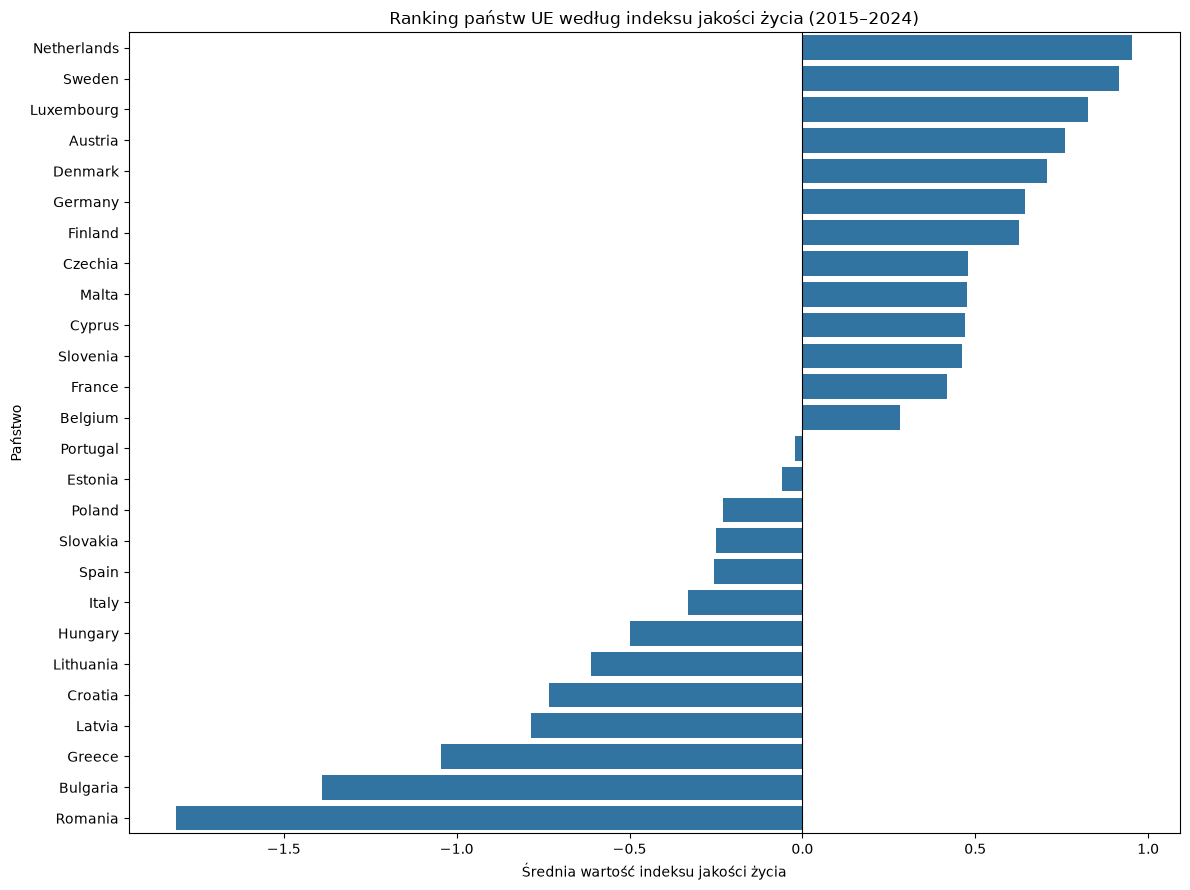

In [114]:
plt.figure(figsize=(12, 9))

sns.barplot(
    data=country_ranking,
    x="quality_of_life_index",
    y="country"
)

plt.title(
    "Ranking państw UE według indeksu jakości życia (2015–2024)"
)
plt.xlabel("Średnia wartość indeksu jakości życia")
plt.ylabel("Państwo")

plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()

plt.savefig(
    "figures/quality_of_life_ranking.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [115]:
gdp_qol = (
    eu_gdp_income_df
    .groupby(["country_code", "country"])
    .agg(avg_gdp_growth=("gdp_growth", "mean"))
    .reset_index()
)

qol_avg = (
    quality_of_life_df
    .groupby(["country_code", "country"])
    .agg(avg_quality_of_life=("quality_of_life_index", "mean"))
    .reset_index()
)

gdp_qol_analysis = pd.merge(
    gdp_qol,
    qol_avg,
    on=["country_code", "country"],
    how="inner"
)

print(gdp_qol_analysis.shape)
print(gdp_qol_analysis.head())

NameError: name 'eu_gdp_income_df' is not defined

In [116]:
eu_gdp_income_df = pd.read_csv(
    "data/processed/eu_gdp_income_2010_2024.csv"
)

print(eu_gdp_income_df.shape)
print(eu_gdp_income_df.head())

(405, 7)
  country_code  country  year  gdp_growth       status_gdp  median_income_pps  \
0           AT  Austria  2010         1.6  brak oznaczenia              19516   
1           AT  Austria  2011         2.6  brak oznaczenia              20425   
2           AT  Austria  2012         0.2  brak oznaczenia              20602   
3           AT  Austria  2013        -0.9  brak oznaczenia              20904   
4           AT  Austria  2014         0.0  brak oznaczenia              21662   

     status_income  
0  brak oznaczenia  
1  brak oznaczenia  
2  brak oznaczenia  
3  brak oznaczenia  
4  brak oznaczenia  


In [117]:
gdp_qol = (
    eu_gdp_income_df
    .groupby(["country_code", "country"])
    .agg(avg_gdp_growth=("gdp_growth", "mean"))
    .reset_index()
)

qol_avg = (
    quality_of_life_df
    .groupby(["country_code", "country"])
    .agg(avg_quality_of_life=("quality_of_life_index", "mean"))
    .reset_index()
)

gdp_qol_analysis = pd.merge(
    gdp_qol,
    qol_avg,
    on=["country_code", "country"],
    how="inner"
)

print("Liczba krajów:", len(gdp_qol_analysis))
print(gdp_qol_analysis.head())

Liczba krajów: 26
  country_code   country  avg_gdp_growth  avg_quality_of_life
0           AT   Austria        0.620000             0.759120
1           BE   Belgium        0.926667             0.283103
2           BG  Bulgaria        3.253333            -1.389669
3           CY    Cyprus        1.946667             0.471643
4           CZ   Czechia        1.606667             0.477630


In [118]:
from scipy.stats import pearsonr, spearmanr

pearson_corr, pearson_p = pearsonr(
    gdp_qol_analysis["avg_gdp_growth"],
    gdp_qol_analysis["avg_quality_of_life"]
)

spearman_corr, spearman_p = spearmanr(
    gdp_qol_analysis["avg_gdp_growth"],
    gdp_qol_analysis["avg_quality_of_life"]
)

print("Korelacja Pearsona:")
print(f"Współczynnik: {pearson_corr:.3f}")
print(f"p-value: {pearson_p:.4f}")

print("\nKorelacja Spearmana:")
print(f"Współczynnik: {spearman_corr:.3f}")
print(f"p-value: {spearman_p:.4f}")

Korelacja Pearsona:
Współczynnik: -0.493
p-value: 0.0105

Korelacja Spearmana:
Współczynnik: -0.434
p-value: 0.0268


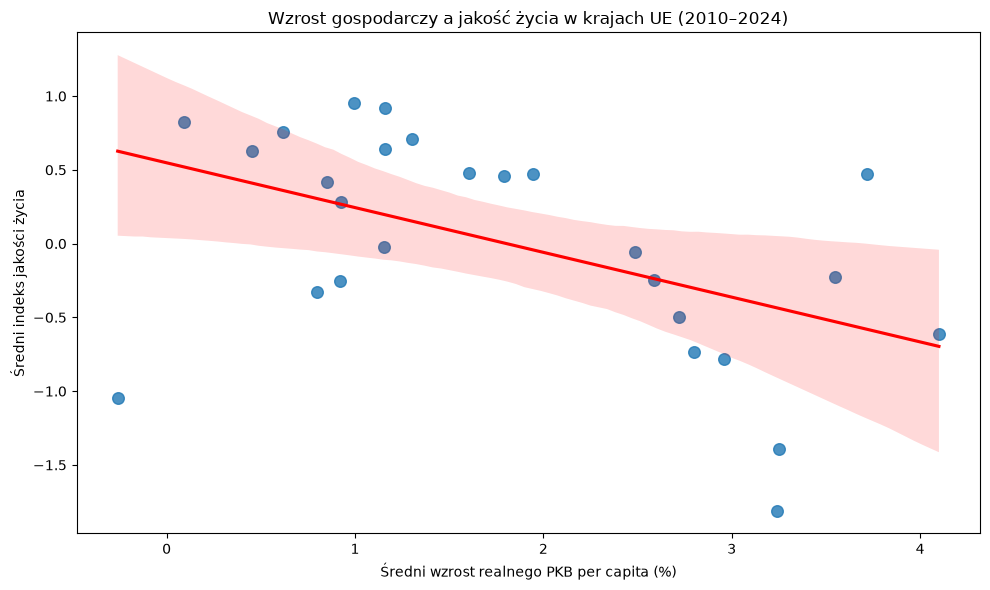

In [119]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=gdp_qol_analysis,
    x="avg_gdp_growth",
    y="avg_quality_of_life",
    scatter_kws={"s": 70},
    line_kws={"color": "red"}
)

plt.title(
    "Wzrost gospodarczy a jakość życia w krajach UE (2010–2024)"
)
plt.xlabel("Średni wzrost realnego PKB per capita (%)")
plt.ylabel("Średni indeks jakości życia")

plt.tight_layout()

plt.savefig(
    "figures/gdp_quality_of_life_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [120]:
from scipy.stats import pearsonr, spearmanr

gdp_qol_2015_2024 = (
    eu_gdp_income_df[
        eu_gdp_income_df["year"].between(2015, 2024)
    ]
    .groupby(["country_code", "country"])
    .agg(avg_gdp_growth=("gdp_growth", "mean"))
    .reset_index()
)

qol_avg = (
    quality_of_life_df
    .groupby(["country_code", "country"])
    .agg(avg_quality_of_life=("quality_of_life_index", "mean"))
    .reset_index()
)

gdp_qol_analysis = pd.merge(
    gdp_qol_2015_2024,
    qol_avg,
    on=["country_code", "country"],
    how="inner",
    validate="one_to_one"
)

pearson_result = pearsonr(
    gdp_qol_analysis["avg_gdp_growth"],
    gdp_qol_analysis["avg_quality_of_life"]
)

spearman_result = spearmanr(
    gdp_qol_analysis["avg_gdp_growth"],
    gdp_qol_analysis["avg_quality_of_life"]
)

print("Liczba krajów:", len(gdp_qol_analysis))
print(f"Korelacja Pearsona: r = {pearson_result.statistic:.3f}, p = {pearson_result.pvalue:.4f}")
print(f"Korelacja Spearmana: rho = {spearman_result.statistic:.3f}, p = {spearman_result.pvalue:.4f}")

Liczba krajów: 26
Korelacja Pearsona: r = -0.611, p = 0.0009
Korelacja Spearmana: rho = -0.644, p = 0.0004


In [121]:
from scipy.stats import pearsonr, spearmanr

sensitivity_results = []

for country in gdp_qol_analysis["country"]:
    temp = gdp_qol_analysis[
        gdp_qol_analysis["country"] != country
    ]

    pearson_r, pearson_p = pearsonr(
        temp["avg_gdp_growth"],
        temp["avg_quality_of_life"]
    )

    spearman_r, spearman_p = spearmanr(
        temp["avg_gdp_growth"],
        temp["avg_quality_of_life"]
    )

    sensitivity_results.append({
        "excluded_country": country,
        "pearson_r": pearson_r,
        "pearson_p": pearson_p,
        "spearman_rho": spearman_r,
        "spearman_p": spearman_p
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

print("Najmniejsza korelacja Pearsona:")
print(sensitivity_df.nsmallest(3, "pearson_r").round(4))

print("\nNajwiększa korelacja Pearsona:")
print(sensitivity_df.nlargest(3, "pearson_r").round(4))

print("\nZakres korelacji Pearsona:")
print(
    sensitivity_df["pearson_r"].min(),
    sensitivity_df["pearson_r"].max()
)

Najmniejsza korelacja Pearsona:
   excluded_country  pearson_r  pearson_p  spearman_rho  spearman_p
3            Cyprus    -0.7110     0.0001       -0.7223      0.0000
18            Malta    -0.6616     0.0003       -0.6846      0.0002
8            Greece    -0.6504     0.0004       -0.6631      0.0003

Największa korelacja Pearsona:
   excluded_country  pearson_r  pearson_p  spearman_rho  spearman_p
22          Romania    -0.5664     0.0032       -0.6154      0.0011
2          Bulgaria    -0.5792     0.0024       -0.6223      0.0009
16       Luxembourg    -0.5830     0.0022       -0.6092      0.0012

Zakres korelacji Pearsona:
-0.710985068667382 -0.5664082824477081


In [122]:
# Dane o wzroście PKB
gdp_panel = eu_gdp_income_df[
    ["country_code", "year", "gdp_growth"]
].copy()

# Dane o indeksie jakości życia
qol_panel = quality_of_life_df[
    ["country_code", "country", "year", "quality_of_life_index"]
].copy()

# Połączenie danych
final_panel_df = pd.merge(
    qol_panel,
    gdp_panel,
    on=["country_code", "year"],
    how="inner",
    validate="one_to_one"
)

# Uporządkowanie danych
final_panel_df = final_panel_df.sort_values(
    ["country_code", "year"]
).reset_index(drop=True)

# Roczna zmiana indeksu jakości życia
final_panel_df["qol_change"] = (
    final_panel_df.groupby("country_code")[
        "quality_of_life_index"
    ].diff()
)

print("Liczba obserwacji:", len(final_panel_df))
print("Liczba krajów:", final_panel_df["country_code"].nunique())
print("Zakres lat:", final_panel_df["year"].min(), "-", final_panel_df["year"].max())

print("\nBraki danych:")
print(final_panel_df[["gdp_growth", "quality_of_life_index", "qol_change"]].isna().sum())

print("\nPodgląd danych:")
display(final_panel_df.head(10))

Liczba obserwacji: 260
Liczba krajów: 26
Zakres lat: 2015 - 2024

Braki danych:
gdp_growth                0
quality_of_life_index     0
qol_change               26
dtype: int64

Podgląd danych:


,country_code,country,year,quality_of_life_index,gdp_growth,qol_change
0,AT,Austria,2015,0.887201,0.3,NaN
1,AT,Austria,2016,0.867005,0.8,-0.020196
2,AT,Austria,2017,0.831956,1.6,-0.035049
3,AT,Austria,2018,0.800071,2.0,-0.031885
4,AT,Austria,2019,0.782186,1.3,-0.017885
5,AT,Austria,2020,0.690321,-6.7,-0.091865
6,AT,Austria,2021,0.670907,4.5,-0.019414
7,AT,Austria,2022,0.648850,4.3,-0.022057
8,AT,Austria,2023,0.711608,-1.5,0.062757
9,AT,Austria,2024,0.701091,-0.8,-0.010517


In [123]:
import statsmodels.formula.api as smf

# Usunięcie pierwszego roku każdego kraju
panel_qol_change = final_panel_df.dropna(
    subset=["qol_change"]
).copy()

# Model z efektami stałymi krajów i lat
panel_model_qol = smf.ols(
    formula="""
        qol_change ~ gdp_growth
        + C(country_code)
        + C(year)
    """,
    data=panel_qol_change
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_qol_change["country_code"]
    }
)

print(panel_model_qol.summary())

                            OLS Regression Results                            
Dep. Variable:             qol_change   R-squared:                       0.200
Model:                            OLS   Adj. R-squared:                  0.063
Method:                 Least Squares   F-statistic:                     14.35
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           7.92e-08
Time:                        17:39:52   Log-Likelihood:                 328.41
No. Observations:                 234   AIC:                            -586.8
Df Residuals:                     199   BIC:                            -465.9
Df Model:                          34                                         
Covariance Type:              cluster                                         
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                -0.02

C:\Users\kamil\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\base\model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 34, but rank is 9
  res = self.wald_test(


In [124]:
# Wzrost PKB z poprzedniego roku
final_panel_df = final_panel_df.sort_values(
    ["country_code", "year"]
).copy()

final_panel_df["gdp_growth_lag1"] = (
    final_panel_df.groupby("country_code")["gdp_growth"].shift(1)
)

# Przygotowanie danych do modelu
panel_qol_lag = final_panel_df.dropna(
    subset=["qol_change", "gdp_growth_lag1"]
).copy()

# Model z opóźnionym wzrostem PKB
panel_model_qol_lag = smf.ols(
    formula="""
        qol_change ~ gdp_growth_lag1
        + C(country_code)
        + C(year)
    """,
    data=panel_qol_lag
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_qol_lag["country_code"]
    }
)

print(panel_model_qol_lag.summary())

                            OLS Regression Results                            
Dep. Variable:             qol_change   R-squared:                       0.227
Model:                            OLS   Adj. R-squared:                  0.095
Method:                 Least Squares   F-statistic:                     10.24
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           2.00e-06
Time:                        17:40:28   Log-Likelihood:                 332.56
No. Observations:                 234   AIC:                            -595.1
Df Residuals:                     199   BIC:                            -474.2
Df Model:                          34                                         
Covariance Type:              cluster                                         
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                -0.03

C:\Users\kamil\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\base\model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 34, but rank is 9
  res = self.wald_test(


In [125]:
panel_model_qol_both = smf.ols(
    formula="""
        qol_change ~ gdp_growth + gdp_growth_lag1
        + C(country_code)
        + C(year)
    """,
    data=panel_qol_lag
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": panel_qol_lag["country_code"]
    }
)

print(panel_model_qol_both.summary())

                            OLS Regression Results                            
Dep. Variable:             qol_change   R-squared:                       0.239
Model:                            OLS   Adj. R-squared:                  0.104
Method:                 Least Squares   F-statistic:                     7.959
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           1.31e-05
Time:                        17:41:03   Log-Likelihood:                 334.28
No. Observations:                 234   AIC:                            -596.6
Df Residuals:                     198   BIC:                            -472.2
Df Model:                          35                                         
Covariance Type:              cluster                                         
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                -0.03

C:\Users\kamil\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\base\model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 35, but rank is 10
  res = self.wald_test(


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import time

from scipy.stats import pearsonr, spearmanr
import statsmodels.api as sm
import statsmodels.formula.api as smf

print("Wszystkie biblioteki załadowane poprawnie!")

Wszystkie biblioteki załadowane poprawnie!


In [2]:
import os

print("Dostępne pliki:")
print(os.listdir("data/processed"))

Dostępne pliki:
['correlation_summary.csv', 'eu_arope_2015_2024.csv', 'eu_employment_2010_2024.csv', 'eu_gdp_income_2010_2024.csv', 'eu_hicp_2010_2024.csv', 'eu_life_expectancy_2010_2024.csv', 'eu_real_median_income_2010_2024.csv', 'gdp_growth_eu27_2010_2024.csv', 'gdp_growth_poland_2010_2024.csv', 'poland_real_income_2010_2024.csv']


In [3]:
eu_gdp_income_df = pd.read_csv(
    "data/processed/eu_gdp_income_2010_2024.csv"
)

income_panel_df = pd.read_csv(
    "data/processed/eu_real_median_income_2010_2024.csv"
)

eu_employment_df = pd.read_csv(
    "data/processed/eu_employment_2010_2024.csv"
)

eu_arope_df = pd.read_csv(
    "data/processed/eu_arope_2015_2024.csv"
)

eu_life_df = pd.read_csv(
    "data/processed/eu_life_expectancy_2010_2024.csv"
)

income_pps_df = eu_gdp_income_df.copy()

print("Dane zostały wczytane poprawnie.")
print("PKB i dochody:", eu_gdp_income_df.shape)
print("Dochody realne:", income_panel_df.shape)
print("Zatrudnienie:", eu_employment_df.shape)
print("AROPE:", eu_arope_df.shape)
print("Długość życia:", eu_life_df.shape)

Dane zostały wczytane poprawnie.
PKB i dochody: (405, 7)
Dochody realne: (405, 11)
Zatrudnienie: (405, 5)
AROPE: (270, 5)
Długość życia: (405, 5)


In [4]:
# Przygotowanie danych dochodowych PPS
income_pps_clean = income_pps_df[
    income_pps_df["country_code"] != "IE"
][["country_code", "year", "median_income_pps"]].copy()

# Połączenie czterech wskaźników jakości życia
quality_of_life_df = income_panel_df[
    ["country_code", "country", "year"]
].copy()

quality_of_life_df = pd.merge(
    quality_of_life_df,
    income_pps_clean,
    on=["country_code", "year"],
    how="inner",
    validate="one_to_one"
)

quality_of_life_df = pd.merge(
    quality_of_life_df,
    eu_employment_df[
        ["country_code", "year", "employment_rate"]
    ],
    on=["country_code", "year"],
    how="inner",
    validate="one_to_one"
)

quality_of_life_df = pd.merge(
    quality_of_life_df,
    eu_arope_df[
        ["country_code", "year", "arope_rate"]
    ],
    on=["country_code", "year"],
    how="inner",
    validate="one_to_one"
)

quality_of_life_df = pd.merge(
    quality_of_life_df,
    eu_life_df[
        ["country_code", "year", "life_expectancy"]
    ],
    on=["country_code", "year"],
    how="inner",
    validate="one_to_one"
)

print("Liczba obserwacji:", len(quality_of_life_df))
print("Liczba krajów:", quality_of_life_df["country_code"].nunique())
print("Lata:", quality_of_life_df["year"].min(), "-", quality_of_life_df["year"].max())
print("\nBraki danych:")
print(quality_of_life_df.isna().sum())

Liczba obserwacji: 260
Liczba krajów: 26
Lata: 2015 - 2024

Braki danych:
country_code         0
country              0
year                 0
median_income_pps    0
employment_rate      0
arope_rate           0
life_expectancy      0
dtype: int64


In [5]:
# Standaryzacja wskaźników w obrębie każdego roku
columns_to_standardize = {
    "median_income_pps": "income_z",
    "employment_rate": "employment_z",
    "arope_rate": "arope_z",
    "life_expectancy": "life_z"
}

for original, standardized in columns_to_standardize.items():
    quality_of_life_df[standardized] = (
        quality_of_life_df.groupby("year")[original]
        .transform(lambda x: (x - x.mean()) / x.std())
    )

# Odwrócenie kierunku wskaźnika AROPE
quality_of_life_df["arope_z_reversed"] = (
    -quality_of_life_df["arope_z"]
)

# Indeks jako średnia czterech wystandaryzowanych wskaźników
quality_of_life_df["quality_of_life_index"] = (
    quality_of_life_df[
        [
            "income_z",
            "employment_z",
            "arope_z_reversed",
            "life_z"
        ]
    ].mean(axis=1)
)

print("Indeks jakości życia został obliczony.")
print(
    quality_of_life_df[
        ["country", "year", "quality_of_life_index"]
    ].head(10).round(3)
)

Indeks jakości życia został obliczony.
   country  year  quality_of_life_index
0  Austria  2015                  0.887
1  Austria  2016                  0.867
2  Austria  2017                  0.832
3  Austria  2018                  0.800
4  Austria  2019                  0.782
5  Austria  2020                  0.690
6  Austria  2021                  0.671
7  Austria  2022                  0.649
8  Austria  2023                  0.712
9  Austria  2024                  0.701


In [6]:
country_ranking = (
    quality_of_life_df
    .groupby(["country_code", "country"])
    ["quality_of_life_index"]
    .mean()
    .reset_index()
    .sort_values("quality_of_life_index", ascending=False)
)

country_ranking["rank"] = range(
    1, len(country_ranking) + 1
)

country_ranking = country_ranking[
    ["rank", "country", "quality_of_life_index"]
]

print("RANKING KRAJÓW UE – INDEKS JAKOŚCI ŻYCIA 2015–2024")
print(country_ranking.round(3).to_string(index=False))

# Zapis rankingu do pliku
country_ranking.to_csv(
    "data/processed/quality_of_life_ranking.csv",
    index=False
)

RANKING KRAJÓW UE – INDEKS JAKOŚCI ŻYCIA 2015–2024
 rank     country  quality_of_life_index
    1 Netherlands                  0.954
    2      Sweden                  0.916
    3  Luxembourg                  0.827
    4     Austria                  0.759
    5     Denmark                  0.708
    6     Germany                  0.645
    7     Finland                  0.625
    8     Czechia                  0.478
    9       Malta                  0.475
   10      Cyprus                  0.472
   11    Slovenia                  0.461
   12      France                  0.417
   13     Belgium                  0.283
   14    Portugal                 -0.023
   15     Estonia                 -0.058
   16      Poland                 -0.229
   17    Slovakia                 -0.249
   18       Spain                 -0.256
   19       Italy                 -0.331
   20     Hungary                 -0.499
   21   Lithuania                 -0.611
   22     Croatia                 -0.733
   23 

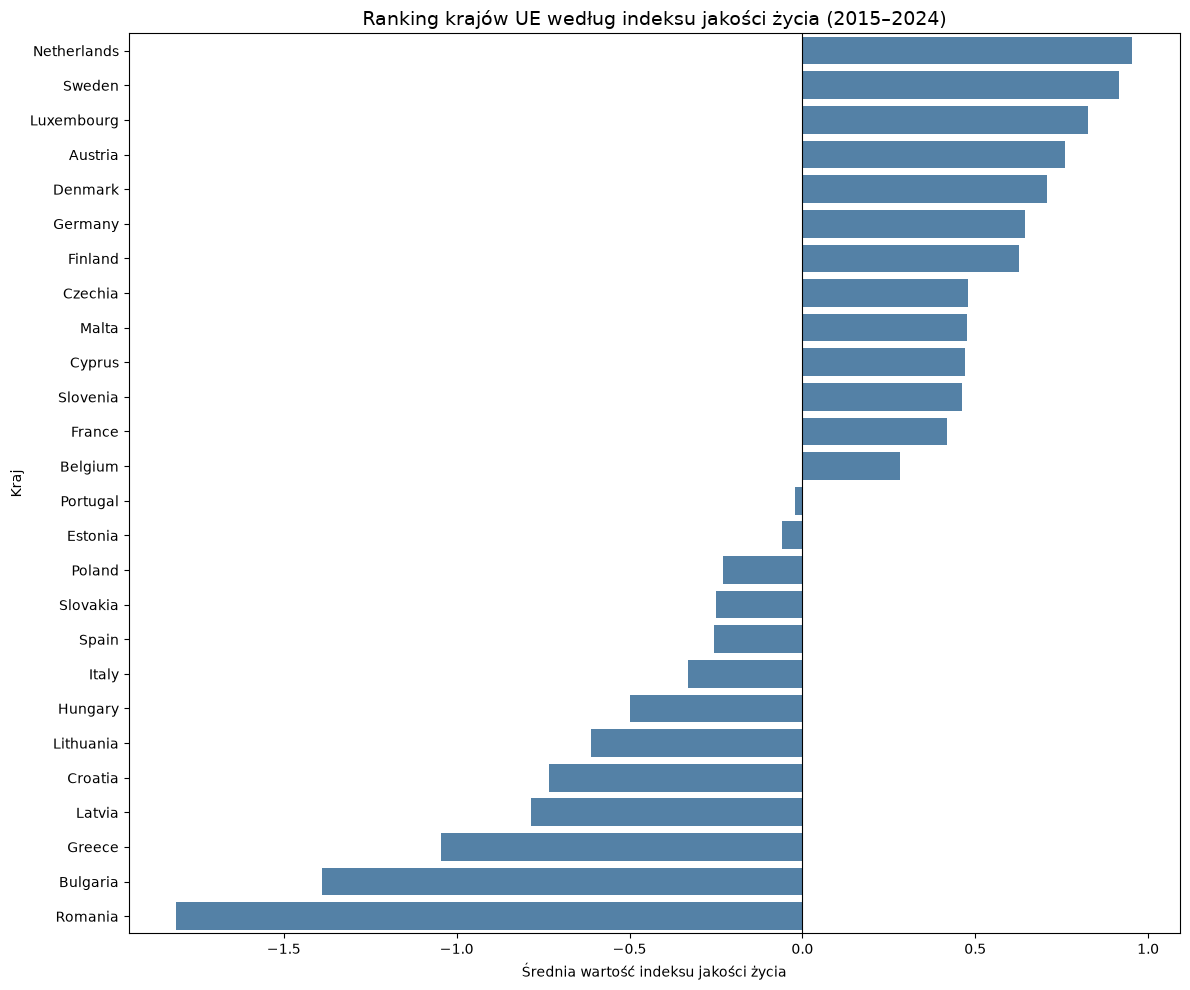

In [7]:
plt.figure(figsize=(12, 10))

sns.barplot(
    data=country_ranking,
    x="quality_of_life_index",
    y="country",
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title(
    "Ranking krajów UE według indeksu jakości życia (2015–2024)",
    fontsize=14
)
plt.xlabel("Średnia wartość indeksu jakości życia")
plt.ylabel("Kraj")
plt.tight_layout()

plt.savefig(
    "figures/quality_of_life_ranking.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
# Średni wzrost PKB w latach 2015–2024
gdp_qol_2015_2024 = (
    eu_gdp_income_df[
        eu_gdp_income_df["year"].between(2015, 2024)
    ]
    .groupby(["country_code", "country"])
    .agg(
        avg_gdp_growth=("gdp_growth", "mean")
    )
    .reset_index()
)

# Średni indeks jakości życia w latach 2015–2024
qol_avg = (
    quality_of_life_df
    .groupby(["country_code", "country"])
    .agg(
        avg_quality_of_life=("quality_of_life_index", "mean")
    )
    .reset_index()
)

# Połączenie danych
gdp_qol_analysis = pd.merge(
    gdp_qol_2015_2024,
    qol_avg,
    on=["country_code", "country"],
    how="inner",
    validate="one_to_one"
)

print("Liczba krajów:", len(gdp_qol_analysis))
print("\nPodgląd danych:")
print(gdp_qol_analysis.head())

Liczba krajów: 26

Podgląd danych:
  country_code   country  avg_gdp_growth  avg_quality_of_life
0           AT   Austria            0.58             0.759120
1           BE   Belgium            1.08             0.283103
2           BG  Bulgaria            3.69            -1.389669
3           CY    Cyprus            4.46             0.471643
4           CZ   Czechia            1.83             0.477630


In [9]:
# Korelacja Pearsona
pearson_r, pearson_p = pearsonr(
    gdp_qol_analysis["avg_gdp_growth"],
    gdp_qol_analysis["avg_quality_of_life"]
)

# Korelacja rang Spearmana
spearman_rho, spearman_p = spearmanr(
    gdp_qol_analysis["avg_gdp_growth"],
    gdp_qol_analysis["avg_quality_of_life"]
)

print("KORELACJA: WZROST PKB A JAKOŚĆ ŻYCIA")
print("--------------------------------------")
print(f"Pearson r: {pearson_r:.3f}")
print(f"Pearson p-value: {pearson_p:.4f}")
print()
print(f"Spearman rho: {spearman_rho:.3f}")
print(f"Spearman p-value: {spearman_p:.4f}")

KORELACJA: WZROST PKB A JAKOŚĆ ŻYCIA
--------------------------------------
Pearson r: -0.611
Pearson p-value: 0.0009

Spearman rho: -0.644
Spearman p-value: 0.0004


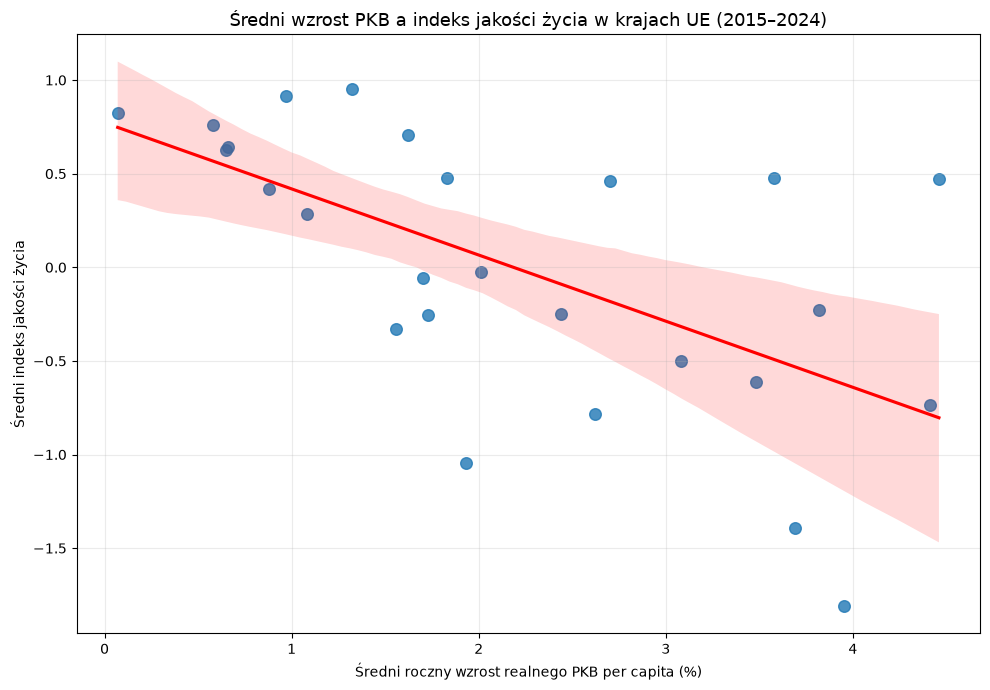

In [10]:
plt.figure(figsize=(10, 7))

sns.regplot(
    data=gdp_qol_analysis,
    x="avg_gdp_growth",
    y="avg_quality_of_life",
    ci=95,
    scatter_kws={"s": 70, "alpha": 0.8},
    line_kws={"color": "red"}
)

plt.title(
    "Średni wzrost PKB a indeks jakości życia w krajach UE (2015–2024)",
    fontsize=13
)
plt.xlabel("Średni roczny wzrost realnego PKB per capita (%)")
plt.ylabel("Średni indeks jakości życia")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    "figures/gdp_quality_of_life_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
sensitivity_results = []

for country in gdp_qol_analysis["country"]:
    temp = gdp_qol_analysis[
        gdp_qol_analysis["country"] != country
    ]

    pearson_r, pearson_p = pearsonr(
        temp["avg_gdp_growth"],
        temp["avg_quality_of_life"]
    )

    spearman_rho, spearman_p = spearmanr(
        temp["avg_gdp_growth"],
        temp["avg_quality_of_life"]
    )

    sensitivity_results.append({
        "excluded_country": country,
        "pearson_r": pearson_r,
        "pearson_p": pearson_p,
        "spearman_rho": spearman_rho,
        "spearman_p": spearman_p
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

print("NAJNIŻSZE WARTOŚCI KORELACJI PEARSONA:")
print(
    sensitivity_df.nsmallest(3, "pearson_r")
    .round(4).to_string(index=False)
)

print("\nNAJWYŻSZE WARTOŚCI KORELACJI PEARSONA:")
print(
    sensitivity_df.nlargest(3, "pearson_r")
    .round(4).to_string(index=False)
)

print("\nZakres korelacji Pearsona:")
print(
    round(sensitivity_df["pearson_r"].min(), 4),
    "do",
    round(sensitivity_df["pearson_r"].max(), 4)
)

NAJNIŻSZE WARTOŚCI KORELACJI PEARSONA:
excluded_country  pearson_r  pearson_p  spearman_rho  spearman_p
          Cyprus    -0.7110     0.0001       -0.7223      0.0000
           Malta    -0.6616     0.0003       -0.6846      0.0002
          Greece    -0.6504     0.0004       -0.6631      0.0003

NAJWYŻSZE WARTOŚCI KORELACJI PEARSONA:
excluded_country  pearson_r  pearson_p  spearman_rho  spearman_p
         Romania    -0.5664     0.0032       -0.6154      0.0011
        Bulgaria    -0.5792     0.0024       -0.6223      0.0009
      Luxembourg    -0.5830     0.0022       -0.6092      0.0012

Zakres korelacji Pearsona:
-0.711 do -0.5664


In [12]:
panel_summary = pd.DataFrame([
    {
        "Obszar": "Zatrudnienie – zmiana roczna",
        "N": 378,
        "Efekt bieżącego PKB": 0.1374,
        "p bieżącego PKB": 0.006,
        "Efekt opóźnionego PKB": 0.1106,
        "p opóźnionego PKB": "<0.001",
        "R-squared": 0.593
    },
    {
        "Obszar": "Długość życia – zmiana roczna",
        "N": 378,
        "Efekt bieżącego PKB": 0.0162,
        "p bieżącego PKB": 0.051,
        "Efekt opóźnionego PKB": -0.0246,
        "p opóźnionego PKB": 0.046,
        "R-squared": 0.472
    },
    {
        "Obszar": "Indeks jakości życia – zmiana roczna",
        "N": 234,
        "Efekt bieżącego PKB": 0.0041,
        "p bieżącego PKB": 0.114,
        "Efekt opóźnionego PKB": 0.0075,
        "p opóźnionego PKB": 0.019,
        "R-squared": 0.239
    }
])

print(panel_summary.round(4).to_string(index=False))

panel_summary.to_csv(
    "data/processed/panel_model_summary.csv",
    index=False
)

                              Obszar   N  Efekt bieżącego PKB  p bieżącego PKB  Efekt opóźnionego PKB p opóźnionego PKB  R-squared
        Zatrudnienie – zmiana roczna 378               0.1374            0.006                 0.1106            <0.001      0.593
       Długość życia – zmiana roczna 378               0.0162            0.051                -0.0246             0.046      0.472
Indeks jakości życia – zmiana roczna 234               0.0041            0.114                 0.0075             0.019      0.239


In [13]:
main_results = pd.DataFrame([
    {
        "Rodzaj analizy": "Przekrojowa",
        "Wymiar": "Realny wzrost mediany dochodu",
        "N": 26,
        "Pearson r": 0.866,
        "Spearman rho": 0.845,
        "Współczynnik regresji": 1.5839,
        "p-value": "<0.001",
        "R-squared": 0.749
    },
    {
        "Rodzaj analizy": "Przekrojowa",
        "Wymiar": "Zmiana wskaźnika zatrudnienia",
        "N": 27,
        "Pearson r": 0.810,
        "Spearman rho": 0.818,
        "Współczynnik regresji": 3.0510,
        "p-value": "<0.001",
        "R-squared": 0.656
    },
    {
        "Rodzaj analizy": "Przekrojowa",
        "Wymiar": "Zmiana wskaźnika AROPE",
        "N": 27,
        "Pearson r": -0.638,
        "Spearman rho": -0.753,
        "Współczynnik regresji": -1.9158,
        "p-value": "<0.001",
        "R-squared": 0.408
    },
    {
        "Rodzaj analizy": "Przekrojowa",
        "Wymiar": "Zmiana oczekiwanej długości życia",
        "N": 27,
        "Pearson r": 0.489,
        "Spearman rho": 0.445,
        "Współczynnik regresji": 0.2806,
        "p-value": "0.0097",
        "R-squared": 0.239
    },
    {
        "Rodzaj analizy": "Przekrojowa",
        "Wymiar": "Średni indeks jakości życia",
        "N": 26,
        "Pearson r": -0.611,
        "Spearman rho": -0.644,
        "Współczynnik regresji": np.nan,
        "p-value": "0.0009 / 0.0004",
        "R-squared": np.nan
    }
])

print(main_results.round(3).to_string(index=False))

main_results.to_csv(
    "data/processed/main_results_summary.csv",
    index=False
)

Rodzaj analizy                            Wymiar  N  Pearson r  Spearman rho  Współczynnik regresji         p-value  R-squared
   Przekrojowa     Realny wzrost mediany dochodu 26      0.866         0.845                  1.584          <0.001      0.749
   Przekrojowa     Zmiana wskaźnika zatrudnienia 27      0.810         0.818                  3.051          <0.001      0.656
   Przekrojowa            Zmiana wskaźnika AROPE 27     -0.638        -0.753                 -1.916          <0.001      0.408
   Przekrojowa Zmiana oczekiwanej długości życia 27      0.489         0.445                  0.281          0.0097      0.239
   Przekrojowa       Średni indeks jakości życia 26     -0.611        -0.644                    NaN 0.0009 / 0.0004        NaN


In [14]:
hypotheses = pd.DataFrame([
    {
        "Hipoteza": "H1",
        "Treść": "Wzrost PKB wiąże się ze wzrostem realnych dochodów.",
        "Wynik": "Dodatnia, silna korelacja (r = 0.866).",
        "Ocena": "Potwierdzona"
    },
    {
        "Hipoteza": "H2",
        "Treść": "Wzrost PKB wiąże się z poprawą sytuacji na rynku pracy.",
        "Wynik": "Dodatnia, silna korelacja (r = 0.810).",
        "Ocena": "Potwierdzona"
    },
    {
        "Hipoteza": "H3",
        "Treść": "Wzrost PKB wiąże się ze spadkiem AROPE.",
        "Wynik": "Ujemna korelacja ze zmianą AROPE (r = -0.638).",
        "Ocena": "Potwierdzona"
    },
    {
        "Hipoteza": "H4",
        "Treść": "Wzrost PKB wiąże się ze wzrostem długości życia.",
        "Wynik": "Dodatnia, umiarkowana korelacja (r = 0.489).",
        "Ocena": "Częściowo potwierdzona"
    },
    {
        "Hipoteza": "H5",
        "Treść": "Wzrost PKB wiąże się z poprawą indeksu jakości życia.",
        "Wynik": "Ujemna korelacja przekrojowa, dodatnia zależność opóźniona w modelu panelowym.",
        "Ocena": "Wyniki niejednoznaczne"
    }
])

print(hypotheses.to_string(index=False))

hypotheses.to_csv(
    "data/processed/hypotheses_summary.csv",
    index=False
)

Hipoteza                                                   Treść                                                                          Wynik                  Ocena
      H1     Wzrost PKB wiąże się ze wzrostem realnych dochodów.                                         Dodatnia, silna korelacja (r = 0.866).           Potwierdzona
      H2 Wzrost PKB wiąże się z poprawą sytuacji na rynku pracy.                                         Dodatnia, silna korelacja (r = 0.810).           Potwierdzona
      H3                 Wzrost PKB wiąże się ze spadkiem AROPE.                                 Ujemna korelacja ze zmianą AROPE (r = -0.638).           Potwierdzona
      H4        Wzrost PKB wiąże się ze wzrostem długości życia.                                   Dodatnia, umiarkowana korelacja (r = 0.489). Częściowo potwierdzona
      H5   Wzrost PKB wiąże się z poprawą indeksu jakości życia. Ujemna korelacja przekrojowa, dodatnia zależność opóźniona w modelu panelowym. Wyniki niejednoznaczn

In [15]:
limitations_text = """
## Ograniczenia badania

1. Badanie ma charakter obserwacyjny, dlatego stwierdzone zależności
statystyczne nie mogą być interpretowane jako związki przyczynowo-skutkowe.

2. Analiza obejmuje 27 państw UE, jednak w przypadku syntetycznego
indeksu jakości życia liczba krajów została ograniczona do 26.
Irlandia została wyłączona ze względu na problemy z porównywalnością
danych dochodowych w analizowanym okresie.

3. Dane dotyczące wskaźnika AROPE są dostępne w analizowanej
postaci od 2015 roku, dlatego indeks jakości życia obejmuje lata
2015–2024, a nie cały okres 2010–2024.

4. W 2021 roku zmieniła się metodologia wskaźnika AROPE.
Pomimo przeliczenia danych historycznych mogą występować
przerwy w szeregach czasowych dla niektórych państw.

5. Syntetyczny indeks jakości życia opiera się na czterech
wskaźnikach o równych wagach. Przyjęte wagi są uproszczeniem
i mogą wpływać na końcowy ranking państw.

6. Indeks jest standaryzowany osobno dla każdego roku.
Oznacza to, że pokazuje względną pozycję państw na tle
pozostałych krajów, a nie bezwzględną zmianę jakości życia.

7. W analizie dochodów zastosowano deflację wskaźnikiem HICP.
Jest to przybliżenie zmian siły nabywczej dochodów, ponieważ
struktura wydatków gospodarstw domowych może różnić się
między państwami.

8. Modele panelowe obejmują ograniczoną liczbę jednostek
przekrojowych (26–27 państw). Wnioskowanie oparte na błędach
standardowych klastrowanych według krajów należy więc
interpretować ostrożnie.

9. Wzrost PKB Irlandii w niektórych latach jest silnie
zniekształcony przez działalność przedsiębiorstw
międzynarodowych i przepływy aktywów niematerialnych.

10. Na wyniki w badanym okresie mogły wpływać nadzwyczajne
wydarzenia, szczególnie pandemia COVID-19 oraz późniejszy
wzrost inflacji.
"""

with open(
    "reports/analiza_wynikow.md",
    "a",
    encoding="utf-8"
) as file:
    file.write("\n\n" + limitations_text)

print("Ograniczenia badania zapisano w pliku analiza_wynikow.md")

Ograniczenia badania zapisano w pliku analiza_wynikow.md


In [16]:
conclusions_text = """
## Wnioski końcowe

Przeprowadzona analiza statystyczna pozwoliła zbadać zależności
między wzrostem gospodarczym a wybranymi wymiarami jakości życia
w państwach Unii Europejskiej w latach 2010–2024.

Uzyskane wyniki wskazują, że wzrost realnego PKB per capita
jest dodatnio związany z poprawą sytuacji dochodowej oraz
sytuacji na rynku pracy. Szczególnie silne zależności
zaobserwowano w przypadku wzrostu realnych dochodów
(Pearson r = 0,866) oraz zmiany wskaźnika zatrudnienia
(Pearson r = 0,810).

Stwierdzono również ujemną zależność między wzrostem PKB
a zmianą wskaźnika zagrożenia ubóstwem lub wykluczeniem
społecznym AROPE (Pearson r = -0,638). Oznacza to, że kraje
osiągające wyższe tempo wzrostu gospodarczego miały
tendencję do odnotowywania większego spadku tego wskaźnika.

W przypadku oczekiwanej długości życia zaobserwowano
umiarkowaną dodatnią zależność przekrojową (Pearson r = 0,489).
Wyniki modeli panelowych były jednak mniej jednoznaczne.
Nie potwierdzono stabilnej dodatniej zależności między
bieżącym lub opóźnionym wzrostem PKB a zmianami długości życia.

Analiza syntetycznego indeksu jakości życia przyniosła
bardziej złożone wyniki. W analizie przekrojowej stwierdzono
ujemną korelację między średnim wzrostem PKB a średnią
względną pozycją państwa w indeksie (Pearson r = -0,611).
Z kolei w modelu panelowym zaobserwowano dodatnią zależność
między opóźnionym wzrostem PKB a roczną zmianą indeksu
(współczynnik = 0,0075; p = 0,019). Bieżący wzrost PKB
nie wykazywał istotnej statystycznie zależności z tą zmianą.

Różnice między wynikami analizy przekrojowej i panelowej
wynikają między innymi z odmiennego sposobu badania zależności.
Analiza przekrojowa porównuje średnie wyniki państw,
natomiast modele panelowe uwzględniają zmiany zachodzące
w obrębie poszczególnych krajów w czasie.

Podsumowując, wyniki wskazują, że wzrost gospodarczy
w państwach UE jest wyraźnie powiązany z poprawą wybranych
materialnych i społecznych wymiarów jakości życia,
szczególnie dochodów, zatrudnienia i ograniczania ubóstwa.
Nie można jednak stwierdzić, że wzrost PKB automatycznie
przekłada się na poprawę wszystkich analizowanych wymiarów.

Ostatecznie jakość życia należy traktować jako zjawisko
wielowymiarowe, którego ocena wymaga uwzględnienia nie tylko
wzrostu gospodarczego, lecz także sytuacji dochodowej,
rynku pracy, poziomu ubóstwa i stanu zdrowia społeczeństwa.

Ze względu na obserwacyjny charakter badania uzyskane wyniki
należy interpretować jako zależności statystyczne,
a nie dowody na występowanie związków przyczynowo-skutkowych.
"""

with open(
    "reports/analiza_wynikow.md",
    "a",
    encoding="utf-8"
) as file:
    file.write("\n\n" + conclusions_text)

print("Wnioski końcowe zapisano w pliku analiza_wynikow.md")

Wnioski końcowe zapisano w pliku analiza_wynikow.md


In [17]:
import os

folders = [
    "data/raw",
    "data/processed",
    "figures",
    "notebooks",
    "reports"
]

for folder in folders:
    print(f"\n📁 {folder}")

    if os.path.exists(folder):
        files = os.listdir(folder)

        if files:
            for file in sorted(files):
                print("   -", file)
        else:
            print("   (folder jest pusty)")
    else:
        print("   (folder nie istnieje)")


📁 data/raw
   - gdp_growth_poland_raw.json

📁 data/processed
   - correlation_summary.csv
   - eu_arope_2015_2024.csv
   - eu_employment_2010_2024.csv
   - eu_gdp_income_2010_2024.csv
   - eu_hicp_2010_2024.csv
   - eu_life_expectancy_2010_2024.csv
   - eu_real_median_income_2010_2024.csv
   - gdp_growth_eu27_2010_2024.csv
   - gdp_growth_poland_2010_2024.csv
   - hypotheses_summary.csv
   - main_results_summary.csv
   - panel_model_summary.csv
   - poland_real_income_2010_2024.csv
   - quality_of_life_ranking.csv

📁 figures
   - .ipynb_checkpoints
   - gdp_arope_relationship.png
   - gdp_employment_relationship.png
   - gdp_life_expectancy_relationship.png
   - gdp_quality_of_life_correlation.png
   - quality_of_life_ranking.png
   - regression_gdp_arope.png
   - regression_gdp_employment.png
   - regression_gdp_income.png
   - regression_gdp_life_expectancy.png

📁 notebooks
   - .ipynb_checkpoints
   - untitled.txt

📁 reports
   - .ipynb_checkpoints
   - analiza_wynikow.md
   - post

In [18]:
import os

print("Notebooki w katalogu głównym:")
for file in os.listdir("."):
    if file.endswith(".ipynb"):
        print("-", file)

print("\nZawartość folderu notebooks:")
print(os.listdir("notebooks"))

Notebooki w katalogu głównym:
- 01_data_collection.ipynb

Zawartość folderu notebooks:
['.ipynb_checkpoints', 'untitled.txt']


In [19]:
import shutil
import os

source = "01_data_collection.ipynb"
destination = "notebooks/01_data_collection.ipynb"

if os.path.exists(source):
    shutil.copy2(source, destination)
    print("Notebook został skopiowany poprawnie.")
    print("Nowa lokalizacja:", destination)
else:
    print("Nie znaleziono pliku źródłowego.")

print("\nCzy kopia istnieje?", os.path.exists(destination))

Notebook został skopiowany poprawnie.
Nowa lokalizacja: notebooks/01_data_collection.ipynb

Czy kopia istnieje? True


In [20]:
readme_text = """
# Wzrost gospodarczy a jakość życia w krajach Unii Europejskiej

## Temat badania

**Wzrost gospodarczy a jakość życia w krajach Unii Europejskiej –
analiza statystyczna danych społeczno-ekonomicznych w latach 2010–2024.**

## Cel badania

Celem projektu jest zbadanie zależności statystycznych między
wzrostem gospodarczym a wybranymi wymiarami jakości życia
w 27 państwach Unii Europejskiej w latach 2010–2024.

Analiza ma charakter ilościowy, porównawczy i obserwacyjny.
Jednostką obserwacji jest kraj w danym roku.

## Zakres badania

- 27 państw Unii Europejskiej.
- Okres analizy: 2010–2024.
- Dane roczne.
- Źródło danych: Eurostat.
- Analiza przekrojowa i panelowa.

## Wykorzystane wskaźniki

1. Roczna stopa wzrostu realnego PKB per capita.
2. Mediana ekwiwalentnego dochodu do dyspozycji.
3. Wskaźnik zatrudnienia osób w wieku 20–64 lata.
4. Wskaźnik zagrożenia ubóstwem lub wykluczeniem społecznym (AROPE).
5. Oczekiwana długość życia w chwili urodzenia.

Dodatkowo skonstruowano syntetyczny indeks jakości życia
oparty na dochodach, zatrudnieniu, wskaźniku AROPE
i oczekiwanej długości życia.

## Metody badawcze

- Statystyki opisowe.
- Korelacja Pearsona.
- Korelacja rang Spearmana.
- Prosta regresja liniowa OLS.
- Modele panelowe z efektami stałymi krajów i lat.
- Błędy standardowe klastrowane według krajów.
- Analiza wrażliwości leave-one-country-out.
- Standaryzacja wskaźników i konstrukcja indeksu syntetycznego.

## Najważniejsze wyniki

W analizie przekrojowej stwierdzono dodatnie zależności
między wzrostem PKB a wzrostem realnych dochodów
(r = 0,866) oraz zmianą wskaźnika zatrudnienia (r = 0,810).

Zaobserwowano również ujemną zależność między wzrostem PKB
a zmianą wskaźnika AROPE (r = -0,638).

Zależność między wzrostem PKB a zmianą oczekiwanej długości
życia była umiarkowanie dodatnia (r = 0,489).

W przypadku syntetycznego indeksu jakości życia uzyskano
ujemną korelację przekrojową (r = -0,611), natomiast
w modelu panelowym stwierdzono dodatnią zależność
z opóźnionym wzrostem PKB.

Wyniki wskazują, że zależności między wzrostem gospodarczym
a jakością życia różnią się w zależności od analizowanego
wymiaru.

## Ograniczenia

Badanie ma charakter obserwacyjny, dlatego nie pozwala
na wnioskowanie przyczynowo-skutkowe.

Indeks jakości życia obejmuje lata 2015–2024 i 26 państw.
Jest standaryzowany osobno dla każdego roku, a zatem
odzwierciedla względną pozycję państw w badanej grupie.

## Struktura projektu

- `data/raw/` – surowe dane źródłowe.
- `data/processed/` – przetworzone zbiory danych i zestawienia wyników.
- `figures/` – wykresy i wizualizacje.
- `notebooks/` – notebooki Jupyter.
- `reports/` – raporty i dokumentacja badania.

## Uruchomienie projektu

Projekt przygotowano w Pythonie i Jupyter Notebook.

Wymagane biblioteki znajdują się w pliku `requirements.txt`.

## Autorstwo i źródło danych

Dane statystyczne pochodzą z bazy Eurostat.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_text)

print("Plik README.md został utworzony.")

Plik README.md został utworzony.


In [21]:
import os

required_files = [
    "README.md",
    "requirements.txt",
    "notebooks/01_data_collection.ipynb",
    "reports/analiza_wynikow.md",
    "data/processed/main_results_summary.csv",
    "data/processed/panel_model_summary.csv",
    "data/processed/hypotheses_summary.csv",
    "figures/quality_of_life_ranking.png",
    "figures/gdp_quality_of_life_correlation.png"
]

for file in required_files:
    if os.path.exists(file):
        print("OK      ", file)
    else:
        print("BRAK    ", file)

OK       README.md
OK       requirements.txt
OK       notebooks/01_data_collection.ipynb
OK       reports/analiza_wynikow.md
OK       data/processed/main_results_summary.csv
OK       data/processed/panel_model_summary.csv
OK       data/processed/hypotheses_summary.csv
OK       figures/quality_of_life_ranking.png
OK       figures/gdp_quality_of_life_correlation.png
